# MandiMitra: Agricultural Market Comparison and Price Intelligence

## Objective

This notebook analyses historical wholesale prices across Indian agricultural markets to identify differences in prices received for the same vegetable under comparable conditions.

It compares prices across markets while controlling for:
- Commodity
- Variety
- Grade
- Arrival date

The analysis examines market-level price premiums and discounts, reporting reliability, historical consistency, and unusual price patterns.

## Key Questions

1. How frequently are the same vegetables reported across multiple markets on the same date?
2. Which markets historically report higher or lower prices than comparable peer markets?
3. How reliable are these comparisons in terms of reporting frequency and available observations?
4. Are observed market-level price differences persistent across multiple years?
5. Which markets demonstrate relatively consistent historical price premiums?

## Dataset Scope

The analysis uses all 46 vegetables included in MandiMitra's cleaned dataset.

The comparison period is January 2021 to October 2025. October 2025 is the latest month selected for the market-comparison analysis because reporting coverage declines substantially afterward.

## Important Limitations

- Historical price premiums do not guarantee future prices or better selling outcomes.
- Comparisons control for recorded commodity, variety, grade, and date, but may not capture all quality differences.
- The dataset does not contain verified transport, handling, or selling costs.
- Unusual observations are investigated and documented rather than automatically treated as errors.

In [2]:
from pathlib import Path

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project paths
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = ROOT / "data" / "processed" / "vegetable_prices_cleaned.parquet"
OUTPUT_DIR = ROOT / "data" / "processed"

# Comparison period
START_DATE = pd.Timestamp("2021-01-01")
END_DATE = pd.Timestamp("2025-10-31")

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Plot settings
sns.set_theme(style="whitegrid")

print("Project root:", ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Project root: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra
Dataset path: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra\data\processed\vegetable_prices_cleaned.parquet
Dataset exists: True


In [3]:
# Connect to the cleaned Parquet dataset
con = duckdb.connect()

# Register the Parquet file as a DuckDB view
con.execute(f"""
    CREATE OR REPLACE VIEW vegetable_prices AS
    SELECT *
    FROM read_parquet('{DATA_PATH.as_posix()}')
""")

# Check dataset structure
schema = con.execute("""
    DESCRIBE vegetable_prices
""").df()

display(schema)

,column_name,column_type,null,key,default,extra
0,State,VARCHAR,YES,None,None,None
1,District,VARCHAR,YES,None,None,None
2,Market,VARCHAR,YES,None,None,None
3,Source_Commodity,VARCHAR,YES,None,None,None
4,Project_Commodity,VARCHAR,YES,None,None,None
5,Variety,VARCHAR,YES,None,None,None
6,Grade,VARCHAR,YES,None,None,None
7,Arrival_Date,VARCHAR,YES,None,None,None
8,Parsed_Date,DATE,YES,None,None,None
9,Min_Price,DOUBLE,YES,None,None,None


In [4]:
import pandas as pd

# Overall dataset statistics (Note the 'f' prefix before the triple quotes)
overview = con.execute(f"""
    SELECT
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT Project_Commodity) AS Total_Vegetables,
        COUNT(DISTINCT State) AS Total_States,
        COUNT(DISTINCT District) AS Total_Districts,
        COUNT(DISTINCT ROW(State, District, Market)) AS Total_Markets,
        COUNT(DISTINCT Variety) AS Total_Varieties,
        COUNT(DISTINCT Grade) AS Total_Grades,
        MIN(Parsed_Date) AS First_Date,
        MAX(Parsed_Date) AS Last_Date,
        COUNT(DISTINCT CASE
            WHEN Parsed_Date BETWEEN DATE '{START_DATE.strftime('%Y-%m-%d')}'
            AND DATE '{END_DATE.strftime('%Y-%m-%d')}'
            THEN Parsed_Date
        END) AS Comparison_Period_Days
    FROM vegetable_prices
""").df()

display(overview)

,Total_Records,Total_Vegetables,Total_States,Total_Districts,Total_Markets,Total_Varieties,Total_Grades,First_Date,Last_Date,Comparison_Period_Days
0,30336319,46,33,616,4550,137,14,2001-01-10,2026-04-20,1765


In [5]:
# Commodity coverage during the comparison period
commodity_coverage = con.execute(f"""
    SELECT
        Project_Commodity,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT State) AS States,
        COUNT(DISTINCT (State, District, Market)) AS Markets,
        COUNT(DISTINCT Variety) AS Varieties,
        COUNT(DISTINCT Parsed_Date) AS Active_Days,
        MIN(Parsed_Date) AS First_Reported_Date,
        MAX(Parsed_Date) AS Last_Reported_Date
    FROM vegetable_prices
    WHERE Parsed_Date BETWEEN DATE '{START_DATE.date()}'
                          AND DATE '{END_DATE.date()}'
    GROUP BY Project_Commodity
    ORDER BY Project_Commodity
""").df()

print("Vegetables in comparison period:", len(commodity_coverage))

display(commodity_coverage)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Vegetables in comparison period: 45


,Project_Commodity,Total_Records,States,Markets,Varieties,Active_Days,First_Reported_Date,Last_Reported_Date
0,Amaranthus,145501,10,393,4,1765,2021-01-01,2025-10-31
1,Beans,116768,17,423,5,1765,2021-01-01,2025-10-31
2,Beetroot,189859,23,512,2,1765,2021-01-01,2025-10-31
3,Bhindi (Ladies Finger),602526,27,1387,2,1765,2021-01-01,2025-10-31
4,Bitter gourd,496790,27,1320,4,1765,2021-01-01,2025-10-31
5,Bottle gourd,538360,26,1143,3,1765,2021-01-01,2025-10-31
6,Brinjal,875061,28,1510,9,1765,2021-01-01,2025-10-31
7,Bunch Beans,3233,2,16,1,1488,2021-01-01,2025-10-31
8,Cabbage,565400,28,1283,3,1765,2021-01-01,2025-10-31
9,Capsicum,243326,24,674,2,1765,2021-01-01,2025-10-31


In [6]:
# Compare full dataset commodities with comparison-period commodities

all_commodities = set(
    con.execute("""
        SELECT DISTINCT Project_Commodity
        FROM vegetable_prices
        WHERE Project_Commodity IS NOT NULL
    """).df()["Project_Commodity"]
)

comparison_commodities = set(commodity_coverage["Project_Commodity"])

missing_commodities = sorted(all_commodities - comparison_commodities)

print("Total commodities in full dataset:", len(all_commodities))
print("Commodities absent from comparison period:", len(missing_commodities))

for commodity in missing_commodities:
    print("-", commodity)

    dates = con.execute(f"""
        SELECT
            MIN(Parsed_Date) AS First_Date,
            MAX(Parsed_Date) AS Last_Date,
            COUNT(*) AS Total_Records
        FROM vegetable_prices
        WHERE Project_Commodity = '{commodity.replace("'", "''")}'
    """).df()

    display(dates)

Total commodities in full dataset: 46
Commodities absent from comparison period: 1
- Elephant Yam (Suran)/Amorphophallus


,First_Date,Last_Date,Total_Records
0,2025-11-29,2026-04-20,6637


### Comparison-Period Coverage

The cleaned dataset contains 46 vegetables overall. However, only 45 have observations during the selected comparison period (January 2021 to October 2025).

Elephant Yam (Suran)/Amorphophallus is absent from this period because its first recorded observation is November 29, 2025. It is therefore excluded from this notebook's historical market comparisons, but remains part of MandiMitra's overall dataset and project scope.

All subsequent comparisons use the 45 vegetables with observations in the selected period.

In [7]:
# Build one observation per market, vegetable, variety, grade and date

con.execute(f"""
    CREATE OR REPLACE TEMP VIEW market_day_prices AS
    SELECT
        TRIM(Project_Commodity) AS Commodity,
        TRIM(Variety) AS Variety,
        TRIM(Grade) AS Grade,
        Parsed_Date AS Arrival_Date,
        TRIM(State) AS State,
        TRIM(District) AS District,
        TRIM(Market) AS Market,

        MEDIAN(Modal_Price) AS Modal_Price,
        COUNT(*) AS Source_Records

    FROM vegetable_prices

    WHERE Parsed_Date BETWEEN DATE '{START_DATE.date()}'
                          AND DATE '{END_DATE.date()}'

      AND Project_Commodity IS NOT NULL
      AND TRIM(Project_Commodity) != ''

      AND Variety IS NOT NULL
      AND TRIM(Variety) != ''

      AND Grade IS NOT NULL
      AND TRIM(Grade) != ''

      AND State IS NOT NULL
      AND TRIM(State) != ''

      AND District IS NOT NULL
      AND TRIM(District) != ''

      AND Market IS NOT NULL
      AND TRIM(Market) != ''

      AND Modal_Price > 0
      AND isfinite(Modal_Price)

    GROUP BY
        TRIM(Project_Commodity),
        TRIM(Variety),
        TRIM(Grade),
        Parsed_Date,
        TRIM(State),
        TRIM(District),
        TRIM(Market)
""")

print("Market-day comparison dataset created.")

Market-day comparison dataset created.


In [8]:
# Validate the market-day comparison dataset

market_day_summary = con.execute("""
    SELECT
        COUNT(*) AS Total_Market_Day_Observations,

        COUNT(DISTINCT Commodity) AS Total_Vegetables,

        COUNT(DISTINCT (State, District, Market))
            AS Total_Markets,

        COUNT(DISTINCT Arrival_Date) AS Active_Dates,

        MIN(Arrival_Date) AS First_Date,
        MAX(Arrival_Date) AS Last_Date,

        MIN(Modal_Price) AS Minimum_Price,
        MEDIAN(Modal_Price) AS Median_Price,
        MAX(Modal_Price) AS Maximum_Price,

        SUM(Source_Records) AS Original_Records_Represented

    FROM market_day_prices
""").df()

display(market_day_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Total_Market_Day_Observations,Total_Vegetables,Total_Markets,Active_Dates,First_Date,Last_Date,Minimum_Price,Median_Price,Maximum_Price,Original_Records_Represented
0,11412781,45,2222,1765,2021-01-01,2025-10-31,1.00,"2,300.00","917,588,483.00","11,412,781.00"


In [9]:
# Check for duplicate market-day keys
duplicate_check = con.execute("""
    SELECT COUNT(*) AS Duplicate_Groups
    FROM (
        SELECT
            Commodity,
            Variety,
            Grade,
            Arrival_Date,
            State,
            District,
            Market,
            COUNT(*) AS Row_Count
        FROM market_day_prices
        GROUP BY
            Commodity,
            Variety,
            Grade,
            Arrival_Date,
            State,
            District,
            Market
        HAVING COUNT(*) > 1
    )
""").df()

# Inspect source-record counts per market-day observation
source_record_summary = con.execute("""
    SELECT
        MIN(Source_Records) AS Minimum_Source_Records,
        MEDIAN(Source_Records) AS Median_Source_Records,
        MAX(Source_Records) AS Maximum_Source_Records,
        COUNT(*) FILTER (WHERE Source_Records > 1)
            AS Multi_Record_Observations
    FROM market_day_prices
""").df()

print("Duplicate key groups:")
display(duplicate_check)

print("Source-record distribution:")
display(source_record_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Duplicate key groups:


,Duplicate_Groups
0,0


Source-record distribution:


,Minimum_Source_Records,Median_Source_Records,Maximum_Source_Records,Multi_Record_Observations
0,1,1.00,1,0


In [10]:
# Count distinct markets reporting comparable prices
comparison_groups = con.execute("""
    SELECT
        Commodity,
        Variety,
        Grade,
        Arrival_Date,

        COUNT(DISTINCT (State, District, Market))
            AS Reporting_Markets

    FROM market_day_prices

    GROUP BY
        Commodity,
        Variety,
        Grade,
        Arrival_Date
""").df()

# Summarise cross-market comparability
comparability_summary = pd.DataFrame({
    "Metric": [
        "Total comparable groups",
        "Groups with at least 2 markets",
        "Groups with at least 3 markets",
        "Groups with at least 5 markets",
        "Groups with at least 10 markets"
    ],
    "Count": [
        len(comparison_groups),
        (comparison_groups["Reporting_Markets"] >= 2).sum(),
        (comparison_groups["Reporting_Markets"] >= 3).sum(),
        (comparison_groups["Reporting_Markets"] >= 5).sum(),
        (comparison_groups["Reporting_Markets"] >= 10).sum()
    ]
})

display(comparability_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Metric,Count
0,Total comparable groups,260607
1,Groups with at least 2 markets,225722
2,Groups with at least 3 markets,207945
3,Groups with at least 5 markets,188013
4,Groups with at least 10 markets,160769


In [11]:
# Evaluate cross-market comparison coverage for each vegetable

comparability_by_commodity = (
    comparison_groups
    .groupby("Commodity")
    .agg(
        Total_Groups=("Reporting_Markets", "size"),
        Groups_2_Markets=("Reporting_Markets", lambda x: (x >= 2).sum()),
        Groups_3_Markets=("Reporting_Markets", lambda x: (x >= 3).sum()),
        Groups_5_Markets=("Reporting_Markets", lambda x: (x >= 5).sum()),
        Groups_10_Markets=("Reporting_Markets", lambda x: (x >= 10).sum())
    )
    .reset_index()
)

comparability_by_commodity["Pct_Groups_3_Markets"] = (
    comparability_by_commodity["Groups_3_Markets"]
    / comparability_by_commodity["Total_Groups"] * 100
)

comparability_by_commodity = comparability_by_commodity.sort_values(
    "Pct_Groups_3_Markets"
)

display(comparability_by_commodity)

,Commodity,Total_Groups,Groups_2_Markets,Groups_3_Markets,Groups_5_Markets,Groups_10_Markets,Pct_Groups_3_Markets
32,Rat Tail Radish (Mogari),595,239,22,0,0,3.70
43,Yam,1227,454,99,0,0,8.07
42,White Pumpkin,2321,1003,301,5,0,12.97
35,Surat Beans (Papadi),2033,1087,595,209,0,29.27
7,Bunch Beans,1531,1122,474,7,0,30.96
16,Duster Beans,1921,1358,752,2,0,39.15
13,Cowpea (Lobia/Karamani),4516,3170,2330,1031,25,51.59
26,Onion,32710,24538,19922,17399,15043,60.90
41,Turnip,2810,2037,1792,1566,1075,63.77
44,Yam (Ratalu),3508,2928,2466,1800,751,70.30


In [12]:
# Evaluate coverage using the minimum peer requirement:
# 1 selected market + at least 3 other peer markets

comparability_by_commodity["Groups_4_Markets"] = (
    comparison_groups
    .groupby("Commodity")["Reporting_Markets"]
    .apply(lambda x: (x >= 4).sum())
    .reindex(comparability_by_commodity["Commodity"])
    .values
)

comparability_by_commodity["Pct_Groups_4_Markets"] = (
    comparability_by_commodity["Groups_4_Markets"]
    / comparability_by_commodity["Total_Groups"] * 100
)

display(
    comparability_by_commodity[
        [
            "Commodity",
            "Total_Groups",
            "Groups_3_Markets",
            "Groups_4_Markets",
            "Groups_5_Markets",
            "Pct_Groups_4_Markets"
        ]
    ].sort_values("Pct_Groups_4_Markets")
)

,Commodity,Total_Groups,Groups_3_Markets,Groups_4_Markets,Groups_5_Markets,Pct_Groups_4_Markets
32,Rat Tail Radish (Mogari),595,22,2,0,0.34
43,Yam,1227,99,11,0,0.90
42,White Pumpkin,2321,301,52,5,2.24
16,Duster Beans,1921,752,107,2,5.57
7,Bunch Beans,1531,474,99,7,6.47
35,Surat Beans (Papadi),2033,595,373,209,18.35
13,Cowpea (Lobia/Karamani),4516,2330,1612,1031,35.70
26,Onion,32710,19922,18402,17399,56.26
44,Yam (Ratalu),3508,2466,2018,1800,57.53
41,Turnip,2810,1792,1651,1566,58.75


In [13]:
# Count market-day observations belonging to groups
# with at least four distinct reporting markets.

eligible_group_summary = con.execute("""
    SELECT
        Commodity,
        COUNT(*) AS Eligible_Comparison_Groups,
        SUM(Reporting_Markets) AS Eligible_Market_Day_Observations,
        MEDIAN(Reporting_Markets) AS Median_Reporting_Markets
    FROM (
        SELECT
            Commodity,
            Variety,
            Grade,
            Arrival_Date,
            COUNT(DISTINCT (State, District, Market))
                AS Reporting_Markets
        FROM market_day_prices
        GROUP BY Commodity, Variety, Grade, Arrival_Date
        HAVING COUNT(DISTINCT (State, District, Market)) >= 4
    )
    GROUP BY Commodity
    ORDER BY Eligible_Market_Day_Observations DESC
""").df()

display(eligible_group_summary)

print(
    "Total eligible comparison groups:",
    eligible_group_summary["Eligible_Comparison_Groups"].sum()
)

print(
    "Total eligible market-day observations:",
    eligible_group_summary["Eligible_Market_Day_Observations"].sum()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Eligible_Comparison_Groups,Eligible_Market_Day_Observations,Median_Reporting_Markets
0,Onion,18402,"985,060.00",23.00
1,Potato,19074,"975,418.00",29.00
2,Tomato,11668,"953,676.00",82.00
3,Brinjal,9919,"874,154.00",90.00
4,Green Chilli,4304,"784,110.00",160.00
5,Bhindi (Ladies Finger),4300,"602,274.00",138.50
6,Cauliflower,8102,"578,076.00",42.00
7,Cabbage,4297,"564,792.00",136.00
8,Bottle gourd,4288,"538,121.00",105.00
9,Bitter gourd,4295,"496,357.00",110.00


Total eligible comparison groups: 196061
Total eligible market-day observations: 11306690.0


In [14]:
# Build a leave-one-market-out peer benchmark.
# Each market is compared against the median price of the other
# markets reporting the same commodity, variety, grade and date.

con.execute("""
    CREATE OR REPLACE TEMP VIEW peer_comparisons AS

    WITH eligible_groups AS (
        SELECT
            Commodity,
            Variety,
            Grade,
            Arrival_Date
        FROM market_day_prices
        GROUP BY
            Commodity,
            Variety,
            Grade,
            Arrival_Date
        HAVING COUNT(DISTINCT (State, District, Market)) >= 4
    ),

    matched_prices AS (
        SELECT
            p.*
        FROM market_day_prices p
        INNER JOIN eligible_groups e
            USING (Commodity, Variety, Grade, Arrival_Date)
    )

    SELECT
        p.Commodity,
        p.Variety,
        p.Grade,
        p.Arrival_Date,
        p.State,
        p.District,
        p.Market,
        p.Modal_Price,
        p.Source_Records,

        COUNT(*) OVER (
            PARTITION BY
                p.Commodity,
                p.Variety,
                p.Grade,
                p.Arrival_Date
        ) - 1 AS Peer_Market_Count,

        (
            SUM(p.Modal_Price) OVER (
                PARTITION BY
                    p.Commodity,
                    p.Variety,
                    p.Grade,
                    p.Arrival_Date
            ) - p.Modal_Price
        ) / NULLIF(
            COUNT(*) OVER (
                PARTITION BY
                    p.Commodity,
                    p.Variety,
                    p.Grade,
                    p.Arrival_Date
            ) - 1,
            0
        ) AS Peer_Mean_Price

    FROM matched_prices p
""")

print("Independent peer comparison view created.")

Independent peer comparison view created.


In [15]:
# Rebuild peer comparisons using a leave-one-market-out median.

con.execute("""
    CREATE OR REPLACE TEMP VIEW peer_comparisons AS

    SELECT
        p.*,

        COUNT(*) OVER (
            PARTITION BY
                Commodity, Variety, Grade, Arrival_Date
        ) - 1 AS Peer_Market_Count,

        MEDIAN(Modal_Price) OVER (
            PARTITION BY
                Commodity, Variety, Grade, Arrival_Date
            ORDER BY Market, State, District
            ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
        ) AS Group_Median_Price

    FROM market_day_prices p

    QUALIFY COUNT(*) OVER (
        PARTITION BY
            Commodity, Variety, Grade, Arrival_Date
    ) >= 4
""")

print("Peer comparison view rebuilt.")

Peer comparison view rebuilt.


In [16]:
# Calculate the median price of other reporting markets,
# excluding the current market from its own benchmark.

con.execute("""
    CREATE OR REPLACE TEMP VIEW peer_comparisons AS

    SELECT
        p.*,

        COUNT(*) OVER peer_window
            AS Peer_Market_Count,

        MEDIAN(Modal_Price) OVER peer_window
            AS Peer_Median_Price

    FROM market_day_prices p

    WINDOW peer_window AS (
        PARTITION BY
            Commodity,
            Variety,
            Grade,
            Arrival_Date
        ORDER BY Market, State, District
        ROWS BETWEEN UNBOUNDED PRECEDING
                 AND UNBOUNDED FOLLOWING
        EXCLUDE CURRENT ROW
    )

    QUALIFY COUNT(*) OVER (
        PARTITION BY
            Commodity,
            Variety,
            Grade,
            Arrival_Date
    ) >= 4
""")

print("Leave-one-market-out peer benchmark created.")

Leave-one-market-out peer benchmark created.


In [17]:
peer_validation = con.execute("""
    SELECT
        COUNT(*) AS Total_Comparisons,

        MIN(Peer_Market_Count) AS Minimum_Peer_Markets,
        MEDIAN(Peer_Market_Count) AS Median_Peer_Markets,
        MAX(Peer_Market_Count) AS Maximum_Peer_Markets,

        COUNT(*) FILTER (
            WHERE Peer_Market_Count < 3
        ) AS Comparisons_With_Fewer_Than_3_Peers,

        COUNT(*) FILTER (
            WHERE Peer_Median_Price IS NULL
        ) AS Missing_Peer_Medians,

        COUNT(*) FILTER (
            WHERE Peer_Median_Price <= 0
        ) AS Non_Positive_Peer_Medians

    FROM peer_comparisons
""").df()

display(peer_validation)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Total_Comparisons,Minimum_Peer_Markets,Median_Peer_Markets,Maximum_Peer_Markets,Comparisons_With_Fewer_Than_3_Peers,Missing_Peer_Medians,Non_Positive_Peer_Medians
0,11306690,3,123.00,348,0,0,0


In [18]:
# Calculate each market's daily price difference
# relative to its independent peer-market median.

con.execute("""
    CREATE OR REPLACE TEMP VIEW market_premium_daily AS

    SELECT
        *,
        Modal_Price - Peer_Median_Price
            AS Price_Difference,

        (
            Modal_Price / Peer_Median_Price - 1
        ) * 100 AS Premium_Discount_Pct,

        Modal_Price / Peer_Median_Price
            AS Price_Ratio

    FROM peer_comparisons
""")

premium_summary = con.execute("""
    SELECT
        COUNT(*) AS Total_Observations,

        MEDIAN(Premium_Discount_Pct)
            AS Median_Premium_Discount_Pct,

        MIN(Premium_Discount_Pct)
            AS Minimum_Premium_Discount_Pct,

        MAX(Premium_Discount_Pct)
            AS Maximum_Premium_Discount_Pct,

        COUNT(*) FILTER (
            WHERE Premium_Discount_Pct > 0
        ) AS Above_Peer_Observations,

        COUNT(*) FILTER (
            WHERE Premium_Discount_Pct < 0
        ) AS Below_Peer_Observations,

        COUNT(*) FILTER (
            WHERE Premium_Discount_Pct = 0
        ) AS Equal_To_Peer_Observations

    FROM market_premium_daily
""").df()

display(premium_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Total_Observations,Median_Premium_Discount_Pct,Minimum_Premium_Discount_Pct,Maximum_Premium_Discount_Pct,Above_Peer_Observations,Below_Peer_Observations,Equal_To_Peer_Observations
0,11306690,0.00,-99.98,"30,791,459.83",5381688,5379760,545242


In [19]:
# Examine the distribution of market premiums and discounts.

premium_distribution = con.execute("""
    SELECT
        QUANTILE_CONT(Premium_Discount_Pct, 0.01)
            AS P01,

        QUANTILE_CONT(Premium_Discount_Pct, 0.05)
            AS P05,

        QUANTILE_CONT(Premium_Discount_Pct, 0.25)
            AS P25,

        MEDIAN(Premium_Discount_Pct)
            AS P50,

        QUANTILE_CONT(Premium_Discount_Pct, 0.75)
            AS P75,

        QUANTILE_CONT(Premium_Discount_Pct, 0.95)
            AS P95,

        QUANTILE_CONT(Premium_Discount_Pct, 0.99)
            AS P99,

        COUNT(*) FILTER (
            WHERE ABS(Premium_Discount_Pct) > 100
        ) AS Beyond_100_Pct,

        COUNT(*) FILTER (
            WHERE ABS(Premium_Discount_Pct) > 500
        ) AS Beyond_500_Pct,

        COUNT(*) FILTER (
            WHERE ABS(Premium_Discount_Pct) > 1000
        ) AS Beyond_1000_Pct

    FROM market_premium_daily
""").df()

display(premium_distribution)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,P01,P05,P25,P50,P75,P95,P99,Beyond_100_Pct,Beyond_500_Pct,Beyond_1000_Pct
0,-73.33,-54.17,-20.21,0.00,26.92,128.57,276.95,802176,32483,13181


In [20]:
# Inspect the 20 largest positive and negative market premiums.

extreme_comparisons = con.execute("""
    (
        SELECT
            'Highest Premiums' AS Extreme_Type,
            Commodity,
            Variety,
            Grade,
            Arrival_Date,
            State,
            District,
            Market,
            Modal_Price,
            Peer_Median_Price,
            Peer_Market_Count,
            Premium_Discount_Pct
        FROM market_premium_daily
        ORDER BY Premium_Discount_Pct DESC
        LIMIT 20
    )

    UNION ALL

    (
        SELECT
            'Largest Discounts' AS Extreme_Type,
            Commodity,
            Variety,
            Grade,
            Arrival_Date,
            State,
            District,
            Market,
            Modal_Price,
            Peer_Median_Price,
            Peer_Market_Count,
            Premium_Discount_Pct
        FROM market_premium_daily
        ORDER BY Premium_Discount_Pct ASC
        LIMIT 20
    )

    ORDER BY Extreme_Type, Premium_Discount_Pct DESC
""").df()

display(extreme_comparisons)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Extreme_Type,Commodity,Variety,Grade,Arrival_Date,State,District,Market,Modal_Price,Peer_Median_Price,Peer_Market_Count,Premium_Discount_Pct
0,Highest Premiums,Onion,Red,FAQ,2024-12-23,Maharashtra,Nashik,Kalvan,"917,588,483.00","2,980.00",183,"30,791,459.83"
1,Highest Premiums,Mint (Pudina),Other,FAQ,2021-12-05,Kerala,Alappuzha,Alappuzha,"10,100.00",3.00,5,"336,566.67"
2,Highest Premiums,Mint (Pudina),Other,FAQ,2021-08-08,Kerala,Alappuzha,Alappuzha,"8,050.00",2.50,4,"321,900.00"
3,Highest Premiums,Mint (Pudina),Other,FAQ,2021-11-14,Kerala,Alappuzha,Alappuzha,"6,050.00",2.00,3,"302,400.00"
4,Highest Premiums,Mint (Pudina),Other,FAQ,2021-08-12,Kerala,Alappuzha,Alappuzha,"8,050.00",3.00,5,"268,233.33"
5,Highest Premiums,Mint (Pudina),Other,FAQ,2021-08-09,Kerala,Alappuzha,Alappuzha,"8,050.00",3.00,7,"268,233.33"
6,Highest Premiums,Mint (Pudina),Other,FAQ,2021-08-07,Kerala,Alappuzha,Alappuzha,"8,050.00",3.00,5,"268,233.33"
7,Highest Premiums,Mint (Pudina),Other,FAQ,2021-08-16,Kerala,Alappuzha,Alappuzha,"8,000.00",3.00,6,"266,566.67"
8,Highest Premiums,Mint (Pudina),Other,FAQ,2021-12-10,Kerala,Alappuzha,Alappuzha,"10,100.00",4.00,7,"252,400.00"
9,Highest Premiums,Mint (Pudina),Other,FAQ,2021-12-09,Kerala,Alappuzha,Alappuzha,"10,100.00",4.00,6,"252,400.00"


In [21]:
# Identify unusually low and unusually high prices.
# These are investigation thresholds, not automatic exclusion rules.

price_anomaly_summary = con.execute("""
    SELECT
        Commodity,

        COUNT(*) AS Total_Observations,

        COUNT(*) FILTER (
            WHERE Modal_Price < 10
        ) AS Prices_Below_10,

        COUNT(*) FILTER (
            WHERE Modal_Price < 50
        ) AS Prices_Below_50,

        COUNT(*) FILTER (
            WHERE Modal_Price > 100000
        ) AS Prices_Above_100000,

        COUNT(*) FILTER (
            WHERE Modal_Price > 1000000
        ) AS Prices_Above_1000000,

        MIN(Modal_Price) AS Minimum_Price,
        MEDIAN(Modal_Price) AS Median_Price,
        MAX(Modal_Price) AS Maximum_Price

    FROM market_day_prices
    GROUP BY Commodity
    ORDER BY Prices_Below_10 DESC, Prices_Above_1000000 DESC
""").df()

display(
    price_anomaly_summary[
        (price_anomaly_summary["Prices_Below_10"] > 0)
        | (price_anomaly_summary["Prices_Above_100000"] > 0)
    ]
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Total_Observations,Prices_Below_10,Prices_Below_50,Prices_Above_100000,Prices_Above_1000000,Minimum_Price,Median_Price,Maximum_Price
0,Spinach,144114,9561,11742,0,0,1.00,"1,000.00","13,000.00"
1,Methi (Leaves),62503,4782,10955,4,0,1.00,"1,200.00","150,000.00"
2,Mint (Pudina),86313,4413,5201,0,0,1.00,"3,700.00","50,000.00"
3,Onion Green,103375,3182,6691,0,0,2.00,"4,500.00","63,000.00"
4,Bottle gourd,538360,26,1828,12,0,3.00,"1,375.00","365,500.00"
5,Tomato,955258,18,688,3,0,5.00,"1,900.00","404,000.00"
6,Cabbage,565400,13,929,6,0,1.00,"1,500.00","700,000.00"
7,Onion,1007024,6,1436,13,1,1.00,"2,000.00","917,588,483.00"
8,Bitter gourd,496790,4,161,37,0,1.70,"3,350.00","500,000.00"
9,Brinjal,875061,3,884,14,0,4.00,"1,850.00","540,000.00"


In [22]:
# Inspect original source records with extremely low or high modal prices.
# Retain quality flags to distinguish known data issues from unexplained anomalies.

extreme_source_records = con.execute("""
    SELECT
        Project_Commodity,
        Variety,
        Grade,
        Parsed_Date,
        State,
        District,
        Market,

        Min_Price,
        Max_Price,
        Modal_Price,

        flag_missing_modal,
        flag_negative_modal,
        flag_zero_range_positive_modal,
        flag_zero_max_positive_min,
        flag_zero_min_positive_max,
        flag_incomplete_range,
        flag_any_price_zero,
        flag_min_gt_max,
        flag_modal_outside_range,
        is_forecast_eligible

    FROM vegetable_prices

    WHERE Parsed_Date BETWEEN DATE '2021-01-01'
                          AND DATE '2025-10-31'

      AND (
          Modal_Price < 10
          OR Modal_Price >= 1000000
      )

    ORDER BY
        CASE
            WHEN Modal_Price >= 1000000 THEN 0
            ELSE 1
        END,
        Modal_Price DESC

    LIMIT 60
""").df()

display(extreme_source_records)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,Variety,Grade,Parsed_Date,State,District,Market,Min_Price,Max_Price,Modal_Price,flag_missing_modal,flag_negative_modal,flag_zero_range_positive_modal,flag_zero_max_positive_min,flag_zero_min_positive_max,flag_incomplete_range,flag_any_price_zero,flag_min_gt_max,flag_modal_outside_range,is_forecast_eligible
0,Onion,Red,FAQ,2024-12-23,Maharashtra,Nashik,Kalvan,"917,588,483.00","917,588,483.00","917,588,483.00",False,False,False,False,False,False,False,False,False,True
1,Green Chilli,Green Chilly,FAQ,2024-07-05,Kerala,Kollam,Valakom VFPCK,"3,900,000.00","4,000,000.00","3,950,000.00",False,False,False,False,False,False,False,False,False,True
2,Ginger (Green),Green Ginger,FAQ,2024-05-23,Kerala,Kollam,Punalur,"2,860,000.00","2,900,000.00","2,880,000.00",False,False,False,False,False,False,False,False,False,True
3,Ginger (Green),Green Ginger,FAQ,2024-06-06,Kerala,Kollam,Punalur,"2,800,000.00","2,840,000.00","2,820,000.00",False,False,False,False,False,False,False,False,False,True
4,Ginger (Green),Green Ginger,FAQ,2024-06-04,Kerala,Kollam,Punalur,"2,800,000.00","2,840,000.00","2,820,000.00",False,False,False,False,False,False,False,False,False,True
5,Ginger (Green),Green Ginger,FAQ,2024-06-03,Kerala,Kollam,Punalur,"2,800,000.00","2,840,000.00","2,820,000.00",False,False,False,False,False,False,False,False,False,True
6,Ginger (Green),Green Ginger,FAQ,2024-06-10,Kerala,Kollam,Punalur,"2,800,000.00","2,840,000.00","2,820,000.00",False,False,False,False,False,False,False,False,False,True
7,Ginger (Green),Green Ginger,FAQ,2024-06-01,Kerala,Kollam,Punalur,"2,700,000.00","2,740,000.00","2,720,000.00",False,False,False,False,False,False,False,False,False,True
8,Ginger (Green),Green Ginger,FAQ,2024-05-22,Kerala,Kollam,Punalur,"2,660,000.00","2,700,000.00","2,680,000.00",False,False,False,False,False,False,False,False,False,True
9,Ginger (Green),Green Ginger,FAQ,2024-05-31,Kerala,Kollam,Punalur,"2,600,000.00","2,640,000.00","2,620,000.00",False,False,False,False,False,False,False,False,False,True


In [23]:
# Summarise extreme prices by physical market.
# This helps identify isolated records versus recurring market-level anomalies.

extreme_market_summary = con.execute("""
    SELECT
        Project_Commodity AS Commodity,
        State,
        District,
        Market,

        COUNT(*) AS Extreme_Records,

        MIN(Parsed_Date) AS First_Occurrence,
        MAX(Parsed_Date) AS Last_Occurrence,

        MEDIAN(Modal_Price) AS Median_Extreme_Price,
        MAX(Modal_Price) AS Maximum_Price,

        COUNT(DISTINCT Parsed_Date) AS Affected_Days

    FROM vegetable_prices

    WHERE Parsed_Date BETWEEN DATE '2021-01-01'
                          AND DATE '2025-10-31'
      AND Modal_Price > 100000
      AND isfinite(Modal_Price)

    GROUP BY
        Project_Commodity,
        State,
        District,
        Market

    ORDER BY Extreme_Records DESC
""").df()

display(extreme_market_summary.head(30))

print("Total market-commodity combinations:", len(extreme_market_summary))
print("Total extreme-price records:", extreme_market_summary["Extreme_Records"].sum())

,Commodity,State,District,Market,Extreme_Records,First_Occurrence,Last_Occurrence,Median_Extreme_Price,Maximum_Price,Affected_Days
0,Garlic,Kerala,Thiruvananthapuram,Pothencode,404,2023-08-18,2025-04-03,"182,040.00","300,040.00",404
1,Ginger (Green),Kerala,Thiruvananthapuram,Pothencode,92,2023-07-10,2024-11-02,"112,040.00","190,040.00",92
2,Garlic,Kerala,Palakad,Kollengode,80,2022-11-24,2023-03-30,"122,000.00","172,000.00",80
3,Drumstick,Kerala,Palakad,Kollengode,56,2022-01-03,2023-02-11,"152,000.00","162,000.00",56
4,Carrot,Himachal Pradesh,Sirmore,Paonta Sahib,53,2022-01-07,2023-04-10,"175,000.00","300,000.00",53
5,Bhindi (Ladies Finger),Himachal Pradesh,Sirmore,Paonta Sahib,39,2022-01-13,2023-06-28,"600,000.00","1,000,000.00",39
6,Bitter gourd,Himachal Pradesh,Sirmore,Paonta Sahib,36,2022-01-19,2023-06-28,"350,000.00","450,000.00",36
7,Indian Beans (Seam),Odisha,Bolangir,Kantabaji,23,2022-01-17,2022-02-28,"500,000.00","600,000.00",23
8,Ginger (Green),Nagaland,Tsemenyu,Tsemenyu,18,2025-01-13,2025-10-27,"310,000.00","350,000.00",18
9,Drumstick,Kerala,Thiruvananthapuram,Pothencode,15,2023-12-16,2024-01-20,"108,040.00","120,040.00",15


Total market-commodity combinations: 52
Total extreme-price records: 936


In [24]:
# Aggregate extreme-price records across commodities
# to identify recurring market-wide reporting patterns.

market_wide_anomalies = con.execute("""
    SELECT
        State,
        District,
        Market,

        COUNT(*) AS Extreme_Records,
        COUNT(DISTINCT Project_Commodity) AS Affected_Commodities,
        COUNT(DISTINCT Parsed_Date) AS Affected_Days,

        MIN(Parsed_Date) AS First_Occurrence,
        MAX(Parsed_Date) AS Last_Occurrence,

        MEDIAN(Modal_Price) AS Median_Extreme_Price,
        MAX(Modal_Price) AS Maximum_Price

    FROM vegetable_prices

    WHERE Parsed_Date BETWEEN DATE '2021-01-01'
                          AND DATE '2025-10-31'
      AND Modal_Price > 100000
      AND isfinite(Modal_Price)

    GROUP BY State, District, Market

    ORDER BY
        Affected_Commodities DESC,
        Extreme_Records DESC
""").df()

display(market_wide_anomalies)

print(
    "Markets with extreme-price records:",
    len(market_wide_anomalies)
)

,State,District,Market,Extreme_Records,Affected_Commodities,Affected_Days,First_Occurrence,Last_Occurrence,Median_Extreme_Price,Maximum_Price
0,Kerala,Thiruvananthapuram,Pothencode,521,6,429,2023-07-10,2025-04-03,"168,040.00","300,040.00"
1,Himachal Pradesh,Sirmore,Paonta Sahib,136,5,80,2022-01-07,2023-08-26,"200,000.00","1,300,000.00"
2,Kerala,Palakad,Kollengode,147,4,99,2022-01-03,2023-03-30,"132,000.00","172,000.00"
3,Kerala,Kollam,Punalur,37,3,15,2024-05-22,2024-08-06,"780,000.00","2,880,000.00"
4,Kerala,Thiruvananthapuram,Attingal,4,3,3,2021-01-23,2023-04-02,"250,000.00","500,000.00"
5,Meghalaya,East Khasi Hills,Sohra,2,2,1,2023-08-17,2023-08-17,"110,000.00","110,000.00"
6,Tamil Nadu,Chengalpattu,Chengalpet (Uzhavar Sandhai ),2,2,2,2024-07-25,2024-08-07,"352,850.00","404,000.00"
7,Odisha,Bolangir,Kantabaji,23,1,23,2022-01-17,2022-02-28,"500,000.00","600,000.00"
8,Nagaland,Tsemenyu,Tsemenyu,18,1,18,2025-01-13,2025-10-27,"310,000.00","350,000.00"
9,Nagaland,Dimapur,Dimapur,6,1,6,2023-10-04,2023-10-10,"300,000.00","330,000.00"


Markets with extreme-price records: 34


In [25]:
# Examine the time distribution of extreme prices
# in the four markets with the strongest multi-commodity signals.

priority_markets = [
    ("Kerala", "Thiruvananthapuram", "Pothencode"),
    ("Himachal Pradesh", "Sirmore", "Paonta Sahib"),
    ("Kerala", "Palakad", "Kollengode"),
    ("Kerala", "Kollam", "Punalur")
]

priority_market_sql = ", ".join(
    f"('{state}', '{district}', '{market}')"
    for state, district, market in priority_markets
)

market_anomaly_timeline = con.execute(f"""
    WITH priority_markets AS (
        SELECT *
        FROM (VALUES {priority_market_sql})
        AS t(State, District, Market)
    )

    SELECT
        p.State,
        p.District,
        p.Market,
        p.Commodity,
        YEAR(p.Arrival_Date) AS Year,

        COUNT(*) AS Extreme_Records,
        COUNT(DISTINCT p.Arrival_Date) AS Affected_Days,

        MEDIAN(p.Modal_Price) AS Median_Price,
        MAX(p.Modal_Price) AS Maximum_Price

    FROM market_day_prices p

    INNER JOIN priority_markets m
        ON p.State = m.State
       AND p.District = m.District
       AND p.Market = m.Market

    WHERE p.Modal_Price >= 100000

    GROUP BY
        p.State,
        p.District,
        p.Market,
        p.Commodity,
        YEAR(p.Arrival_Date)

    ORDER BY
        p.State,
        p.District,
        p.Market,
        Year,
        p.Commodity
""").df()

display(market_anomaly_timeline)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,District,Market,Commodity,Year,Extreme_Records,Affected_Days,Median_Price,Maximum_Price
0,Himachal Pradesh,Sirmore,Paonta Sahib,Bhindi (Ladies Finger),2022,16,16,"625,000.00","700,000.00"
1,Himachal Pradesh,Sirmore,Paonta Sahib,Bitter gourd,2022,7,7,"200,000.00","250,000.00"
2,Himachal Pradesh,Sirmore,Paonta Sahib,Carrot,2022,29,29,"175,000.00","225,000.00"
3,Himachal Pradesh,Sirmore,Paonta Sahib,Bhindi (Ladies Finger),2023,23,23,"550,000.00","1,000,000.00"
4,Himachal Pradesh,Sirmore,Paonta Sahib,Bitter gourd,2023,29,29,"350,000.00","450,000.00"
5,Himachal Pradesh,Sirmore,Paonta Sahib,Carrot,2023,24,24,"150,000.00","300,000.00"
6,Himachal Pradesh,Sirmore,Paonta Sahib,Garlic,2023,6,6,"1,225,000.00","1,300,000.00"
7,Himachal Pradesh,Sirmore,Paonta Sahib,Sponge gourd,2023,2,2,"300,000.00","310,000.00"
8,Kerala,Kollam,Punalur,Brinjal,2024,14,14,"480,000.00","540,000.00"
9,Kerala,Kollam,Punalur,Cowpea (Veg),2024,14,14,"800,000.00","1,280,000.00"


In [27]:
# Compare suspect markets with their matched peer-market medians.
# This checks whether their prices are unusually high relative
# to other markets reporting the same commodity, variety, grade and date.

suspect_market_comparison = con.execute("""
    SELECT
        State,
        District,
        Market,
        YEAR(Arrival_Date) AS Year,

        COUNT(*) AS Matched_Observations,

        MEDIAN(Modal_Price) AS Median_Market_Price,
        MEDIAN(Peer_Median_Price) AS Median_Peer_Price,
        MEDIAN(Price_Ratio) AS Median_Price_Ratio,

        COUNT(*) FILTER (
            WHERE Price_Ratio > 2
        ) AS Days_Above_2x_Peers,

        COUNT(*) FILTER (
            WHERE Price_Ratio > 5
        ) AS Days_Above_5x_Peers,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE Price_Ratio > 2
            ) / COUNT(*),
            2
        ) AS Pct_Days_Above_2x

    FROM market_premium_daily

    WHERE
        (State = 'Kerala'
         AND District = 'Thiruvananthapuram'
         AND Market = 'Pothencode')

        OR

        (State = 'Himachal Pradesh'
         AND District = 'Sirmore'
         AND Market = 'Paonta Sahib')

        OR

        (State = 'Kerala'
         AND District = 'Palakad'
         AND Market = 'Kollengode')

        OR

        (State = 'Kerala'
         AND District = 'Kollam'
         AND Market = 'Punalur')

    GROUP BY
        State,
        District,
        Market,
        YEAR(Arrival_Date)

    ORDER BY
        State,
        District,
        Market,
        Year
""").df()

display(suspect_market_comparison)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,District,Market,Year,Matched_Observations,Median_Market_Price,Median_Peer_Price,Median_Price_Ratio,Days_Above_2x_Peers,Days_Above_5x_Peers,Pct_Days_Above_2x
0,Himachal Pradesh,Sirmore,Paonta Sahib,2021,2276,"2,000.00","1,775.00",1.06,37,0,1.63
1,Himachal Pradesh,Sirmore,Paonta Sahib,2022,1958,"2,500.00","2,225.00",1.17,105,53,5.36
2,Himachal Pradesh,Sirmore,Paonta Sahib,2023,2572,"2,500.00","2,100.00",1.19,166,85,6.45
3,Himachal Pradesh,Sirmore,Paonta Sahib,2024,2892,"2,800.00","2,600.00",1.11,81,1,2.80
4,Himachal Pradesh,Sirmore,Paonta Sahib,2025,2300,"2,500.00","2,400.00",1.09,43,0,1.87
5,Kerala,Kollam,Punalur,2021,1035,"5,600.00","2,500.00",2.17,553,42,53.43
6,Kerala,Kollam,Punalur,2022,2611,"4,800.00","2,500.00",1.80,1052,115,40.29
7,Kerala,Kollam,Punalur,2023,2303,"4,200.00","2,700.00",1.73,883,30,38.34
8,Kerala,Kollam,Punalur,2024,2183,"4,800.00","3,200.00",1.52,517,64,23.68
9,Kerala,Kollam,Punalur,2025,2929,"4,200.00","3,000.00",1.78,1148,19,39.19


In [28]:
# Evaluate only extreme-price observations against their
# leave-one-market-out peer benchmarks.

extreme_peer_analysis = con.execute("""
    SELECT
        State,
        District,
        Market,
        Commodity,
        YEAR(Arrival_Date) AS Year,

        COUNT(*) AS Extreme_Observations,

        MEDIAN(Modal_Price) AS Median_Extreme_Price,
        MEDIAN(Peer_Median_Price) AS Median_Peer_Price,
        MEDIAN(Price_Ratio) AS Median_Price_Ratio,

        COUNT(*) FILTER (
            WHERE Price_Ratio > 2
        ) AS Observations_Above_2x,

        COUNT(*) FILTER (
            WHERE Price_Ratio > 5
        ) AS Observations_Above_5x,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE Price_Ratio > 5
            ) / COUNT(*),
            2
        ) AS Pct_Above_5x

    FROM market_premium_daily

    WHERE Modal_Price > 100000

    GROUP BY
        State,
        District,
        Market,
        Commodity,
        YEAR(Arrival_Date)

    ORDER BY
        Extreme_Observations DESC
""").df()

display(extreme_peer_analysis)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,District,Market,Commodity,Year,Extreme_Observations,Median_Extreme_Price,Median_Peer_Price,Median_Price_Ratio,Observations_Above_2x,Observations_Above_5x,Pct_Above_5x
0,Kerala,Thiruvananthapuram,Pothencode,Garlic,2024,285,"192,040.00","13,440.00",13.29,285,285,100.00
1,Kerala,Thiruvananthapuram,Pothencode,Garlic,2025,76,"198,040.00","10,000.00",17.95,76,76,100.00
2,Kerala,Palakad,Kollengode,Garlic,2023,66,"122,000.00","3,962.50",33.17,66,66,100.00
3,Kerala,Thiruvananthapuram,Pothencode,Ginger (Green),2024,65,"108,040.00","9,025.00",11.70,65,65,100.00
4,Kerala,Thiruvananthapuram,Pothencode,Garlic,2023,43,"137,540.00","9,950.00",12.65,43,43,100.00
5,Kerala,Palakad,Kollengode,Drumstick,2022,30,"131,000.00","13,250.00",9.96,30,30,100.00
6,Himachal Pradesh,Sirmore,Paonta Sahib,Carrot,2022,29,"175,000.00","1,200.00",125.00,29,29,100.00
7,Himachal Pradesh,Sirmore,Paonta Sahib,Bitter gourd,2023,29,"350,000.00","3,500.00",100.00,29,29,100.00
8,Kerala,Thiruvananthapuram,Pothencode,Ginger (Green),2023,27,"128,040.00","10,000.00",12.88,27,27,100.00
9,Kerala,Palakad,Kollengode,Drumstick,2023,26,"152,000.00","10,625.00",14.31,26,26,100.00


In [29]:
# Identify market-years with prices at least 5 times
# the matched peer-market median across multiple commodities.

market_year_anomaly_clusters = con.execute("""
    SELECT
        State,
        District,
        Market,
        YEAR(Arrival_Date) AS Year,

        COUNT(*) AS Extreme_Observations,
        COUNT(DISTINCT Commodity) AS Affected_Commodities,
        COUNT(DISTINCT Arrival_Date) AS Affected_Days,

        MEDIAN(Price_Ratio) AS Median_Price_Ratio,
        MAX(Price_Ratio) AS Maximum_Price_Ratio

    FROM market_premium_daily

    WHERE Price_Ratio >= 5

    GROUP BY
        State,
        District,
        Market,
        YEAR(Arrival_Date)

    HAVING COUNT(DISTINCT Commodity) >= 2

    ORDER BY
        Affected_Commodities DESC,
        Extreme_Observations DESC
""").df()

display(market_year_anomaly_clusters)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,District,Market,Year,Extreme_Observations,Affected_Commodities,Affected_Days,Median_Price_Ratio,Maximum_Price_Ratio
0,Kerala,Palakad,Kollengode,2022,3782,22,183,13.37,65.00
1,Kerala,Thiruvananthapuram,Pothencode,2024,5485,21,290,10.42,43.36
2,Kerala,Thiruvananthapuram,Pothencode,2023,3175,21,225,8.66,27.31
3,Kerala,Thiruvananthapuram,Pothencode,2025,1505,21,97,14.21,83.89
4,Kerala,Palakad,Kollengode,2023,1370,21,66,15.71,74.29
...,...,...,...,...,...,...,...,...,...
675,Nagaland,Longleng,Longleng,2025,2,2,2,5.16,5.25
676,Tamil Nadu,Kancheepuram,Padappai (Uzhavar Sandhai ),2024,2,2,2,6.81,7.37
677,Maharashtra,Satara,Vai,2023,2,2,2,5.81,6.43
678,Tamil Nadu,Cuddalore,Viruthachalam (Uzhavar Sandhai ),2024,2,2,2,15.05,20.00


In [30]:
# Explicit register of market-years with strong evidence
# of market-wide price-scale anomalies.

anomaly_register = pd.DataFrame([
    {
        "State": "Kerala",
        "District": "Thiruvananthapuram",
        "Market": "Pothencode",
        "Start_Date": "2023-01-01",
        "End_Date": "2025-10-31",
        "Reason": (
            "Persistent extreme premiums across 21 commodities "
            "in each affected year"
        ),
        "Treatment": "Exclude from primary rankings"
    },
    {
        "State": "Kerala",
        "District": "Palakad",
        "Market": "Kollengode",
        "Start_Date": "2022-01-01",
        "End_Date": "2023-12-31",
        "Reason": (
            "Extreme peer-relative prices across 22 commodities "
            "in 2022 and 21 in 2023"
        ),
        "Treatment": "Exclude from primary rankings"
    }
])

anomaly_register["Start_Date"] = pd.to_datetime(
    anomaly_register["Start_Date"]
)

anomaly_register["End_Date"] = pd.to_datetime(
    anomaly_register["End_Date"]
)

display(anomaly_register)

,State,District,Market,Start_Date,End_Date,Reason,Treatment
0,Kerala,Thiruvananthapuram,Pothencode,2023-01-01,2025-10-31,Persistent extreme premiums across 21 commodit...,Exclude from primary rankings
1,Kerala,Palakad,Kollengode,2022-01-01,2023-12-31,Extreme peer-relative prices across 22 commodi...,Exclude from primary rankings


In [31]:
# Register the anomaly table with DuckDB for matching.

con.register("anomaly_register_df", anomaly_register)

exclusion_impact = con.execute("""
    SELECT
        r.State,
        r.District,
        r.Market,
        r.Start_Date,
        r.End_Date,

        COUNT(p.Commodity) AS Observations_To_Exclude,

        COUNT(DISTINCT p.Commodity) AS Affected_Commodities,

        COUNT(DISTINCT p.Arrival_Date) AS Affected_Days

    FROM anomaly_register_df r

    LEFT JOIN market_day_prices p
        ON p.State = r.State
       AND p.District = r.District
       AND p.Market = r.Market
       AND p.Arrival_Date BETWEEN
           CAST(r.Start_Date AS DATE)
           AND CAST(r.End_Date AS DATE)

    GROUP BY
        r.State,
        r.District,
        r.Market,
        r.Start_Date,
        r.End_Date

    ORDER BY r.Market
""").df()

display(exclusion_impact)

print(
    "Total observations proposed for exclusion:",
    exclusion_impact["Observations_To_Exclude"].sum()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,District,Market,Start_Date,End_Date,Observations_To_Exclude,Affected_Commodities,Affected_Days
0,Kerala,Palakad,Kollengode,2022-01-01,2023-12-31,7823,23,467
1,Kerala,Thiruvananthapuram,Pothencode,2023-01-01,2025-10-31,14881,21,765


Total observations proposed for exclusion: 22704


In [32]:
# Break down proposed exclusions by market and year.

exclusion_yearly_impact = con.execute("""
    SELECT
        r.Market,
        YEAR(p.Arrival_Date) AS Year,

        COUNT(*) AS Observations_To_Exclude,
        COUNT(DISTINCT p.Commodity) AS Affected_Commodities,
        COUNT(DISTINCT p.Arrival_Date) AS Affected_Days,

        MEDIAN(p.Modal_Price) AS Median_Price,
        MAX(p.Modal_Price) AS Maximum_Price

    FROM anomaly_register_df r

    INNER JOIN market_day_prices p
        ON p.State = r.State
       AND p.District = r.District
       AND p.Market = r.Market
       AND p.Arrival_Date BETWEEN
           CAST(r.Start_Date AS DATE)
           AND CAST(r.End_Date AS DATE)

    GROUP BY
        r.Market,
        YEAR(p.Arrival_Date)

    ORDER BY
        r.Market,
        Year
""").df()

display(exclusion_yearly_impact)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Market,Year,Observations_To_Exclude,Affected_Commodities,Affected_Days,Median_Price,Maximum_Price
0,Kollengode,2022,3795,23,183,"35,000.00","160,000.00"
1,Kollengode,2023,4028,22,284,"6,300.00","172,000.00"
2,Pothencode,2023,4646,21,227,"16,040.00","195,040.00"
3,Pothencode,2024,6009,21,290,"32,540.00","300,040.00"
4,Pothencode,2025,4226,21,248,"7,000.00","234,040.00"


In [33]:
# Refine exclusions to preserve potentially valid observations.

anomaly_register = pd.DataFrame([
    {
        "State": "Kerala",
        "District": "Palakad",
        "Market": "Kollengode",
        "Start_Date": "2022-01-01",
        "End_Date": "2022-12-31",
        "Exclusion_Scope": "FULL_MARKET_YEAR",
        "Peer_Ratio_Threshold": None,
        "Reason": "Severe market-wide anomaly across 23 commodities"
    },
    {
        "State": "Kerala",
        "District": "Palakad",
        "Market": "Kollengode",
        "Start_Date": "2023-01-01",
        "End_Date": "2023-12-31",
        "Exclusion_Scope": "EXTREME_OBSERVATIONS_ONLY",
        "Peer_Ratio_Threshold": 5.0,
        "Reason": "Targeted exclusion of observations exceeding 5x peer median"
    },
    {
        "State": "Kerala",
        "District": "Thiruvananthapuram",
        "Market": "Pothencode",
        "Start_Date": "2023-01-01",
        "End_Date": "2025-10-31",
        "Exclusion_Scope": "FULL_MARKET_YEAR",
        "Peer_Ratio_Threshold": None,
        "Reason": "Persistent market-wide anomaly across 21 commodities"
    }
])

anomaly_register["Start_Date"] = pd.to_datetime(
    anomaly_register["Start_Date"]
)

anomaly_register["End_Date"] = pd.to_datetime(
    anomaly_register["End_Date"]
)

display(anomaly_register)

,State,District,Market,Start_Date,End_Date,Exclusion_Scope,Peer_Ratio_Threshold,Reason
0,Kerala,Palakad,Kollengode,2022-01-01,2022-12-31,FULL_MARKET_YEAR,NaN,Severe market-wide anomaly across 23 commodities
1,Kerala,Palakad,Kollengode,2023-01-01,2023-12-31,EXTREME_OBSERVATIONS_ONLY,5.00,Targeted exclusion of observations exceeding 5...
2,Kerala,Thiruvananthapuram,Pothencode,2023-01-01,2025-10-31,FULL_MARKET_YEAR,NaN,Persistent market-wide anomaly across 21 commo...


In [34]:
# Correct the targeted 2023 condition to use the joined peer ratio.

con.execute("""
    CREATE OR REPLACE TEMP VIEW market_day_prices_reviewed AS

    SELECT
        p.*,

        CASE
            WHEN p.State = 'Kerala'
             AND p.District = 'Palakad'
             AND p.Market = 'Kollengode'
             AND p.Arrival_Date BETWEEN DATE '2022-01-01'
                                    AND DATE '2022-12-31'
                THEN 'KOLLENGODE_2022_MARKET_WIDE'

            WHEN p.State = 'Kerala'
             AND p.District = 'Palakad'
             AND p.Market = 'Kollengode'
             AND p.Arrival_Date BETWEEN DATE '2023-01-01'
                                    AND DATE '2023-12-31'
             AND d.Price_Ratio >= 5
                THEN 'KOLLENGODE_2023_EXTREME'

            WHEN p.State = 'Kerala'
             AND p.District = 'Thiruvananthapuram'
             AND p.Market = 'Pothencode'
             AND p.Arrival_Date BETWEEN DATE '2023-01-01'
                                    AND DATE '2025-10-31'
                THEN 'POTHENCODE_MARKET_WIDE'

            ELSE NULL
        END AS Exclusion_Reason

    FROM market_day_prices p

    LEFT JOIN market_premium_daily d
        USING (
            Commodity, Variety, Grade, Arrival_Date,
            State, District, Market
        )
""")

print("Reviewed market-day dataset created.")

Reviewed market-day dataset created.


In [36]:
# Validate the reviewed dataset and summarise exclusion reasons.

reviewed_summary = con.execute("""
    SELECT
        COUNT(*) AS Total_Observations,

        COUNT(*) FILTER (
            WHERE Exclusion_Reason IS NULL
        ) AS Retained_Observations,

        COUNT(*) FILTER (
            WHERE Exclusion_Reason IS NOT NULL
        ) AS Excluded_Observations,

        COUNT(DISTINCT Commodity) FILTER (
            WHERE Exclusion_Reason IS NULL
        ) AS Retained_Commodities

    FROM market_day_prices_reviewed
""").df()

exclusion_breakdown = con.execute("""
    SELECT
        Exclusion_Reason,
        COUNT(*) AS Excluded_Observations,
        COUNT(DISTINCT Commodity) AS Affected_Commodities,
        COUNT(DISTINCT Arrival_Date) AS Affected_Days

    FROM market_day_prices_reviewed

    WHERE Exclusion_Reason IS NOT NULL

    GROUP BY Exclusion_Reason
    ORDER BY Excluded_Observations DESC
""").df()

display(reviewed_summary)
display(exclusion_breakdown)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Total_Observations,Retained_Observations,Excluded_Observations,Retained_Commodities
0,11412781,11392735,20046,45


,Exclusion_Reason,Excluded_Observations,Affected_Commodities,Affected_Days
0,POTHENCODE_MARKET_WIDE,14881,21,765
1,KOLLENGODE_2022_MARKET_WIDE,3795,23,183
2,KOLLENGODE_2023_EXTREME,1370,21,66


In [37]:
# Rebuild leave-one-market-out peer comparisons
# using only retained market-day observations.

con.execute("""
    CREATE OR REPLACE TEMP VIEW peer_comparisons_reviewed AS

    SELECT
        p.*,

        COUNT(*) OVER peer_window
            AS Peer_Market_Count,

        MEDIAN(Modal_Price) OVER peer_window
            AS Peer_Median_Price

    FROM market_day_prices_reviewed p

    WHERE Exclusion_Reason IS NULL

    WINDOW peer_window AS (
        PARTITION BY
            Commodity,
            Variety,
            Grade,
            Arrival_Date
        ORDER BY Market, State, District
        ROWS BETWEEN UNBOUNDED PRECEDING
                 AND UNBOUNDED FOLLOWING
        EXCLUDE CURRENT ROW
    )

    QUALIFY COUNT(*) OVER (
        PARTITION BY
            Commodity,
            Variety,
            Grade,
            Arrival_Date
    ) >= 4
""")

# Calculate each retained market's premium or discount
# relative to the median of its other reporting markets.

con.execute("""
    CREATE OR REPLACE TEMP VIEW market_premium_daily_reviewed AS

    SELECT
        *,

        Modal_Price - Peer_Median_Price
            AS Price_Difference,

        (
            Modal_Price / Peer_Median_Price - 1
        ) * 100 AS Premium_Discount_Pct,

        Modal_Price / Peer_Median_Price
            AS Price_Ratio

    FROM peer_comparisons_reviewed
""")

print("Reviewed peer comparisons and daily premiums created.")

Reviewed peer comparisons and daily premiums created.


In [38]:
# Validate the rebuilt peer comparisons.

peer_validation_reviewed = con.execute("""
    SELECT
        COUNT(*) AS Total_Comparisons,

        COUNT(DISTINCT Commodity) AS Total_Commodities,

        COUNT(DISTINCT (State, District, Market))
            AS Total_Markets,

        MIN(Peer_Market_Count) AS Minimum_Peer_Markets,
        MEDIAN(Peer_Market_Count) AS Median_Peer_Markets,
        MAX(Peer_Market_Count) AS Maximum_Peer_Markets,

        COUNT(*) FILTER (
            WHERE Peer_Market_Count < 3
        ) AS Comparisons_With_Fewer_Than_3_Peers,

        COUNT(*) FILTER (
            WHERE Peer_Median_Price IS NULL
        ) AS Missing_Peer_Medians,

        COUNT(*) FILTER (
            WHERE Peer_Median_Price <= 0
        ) AS Non_Positive_Peer_Medians

    FROM market_premium_daily_reviewed
""").df()

display(peer_validation_reviewed)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Total_Comparisons,Total_Commodities,Total_Markets,Minimum_Peer_Markets,Median_Peer_Markets,Maximum_Peer_Markets,Comparisons_With_Fewer_Than_3_Peers,Missing_Peer_Medians,Non_Positive_Peer_Medians
0,11286611,45,2211,3,123.00,348,0,0,0


In [39]:
# Measure how much usable comparison data remains for each vegetable.

coverage_reviewed = con.execute("""
    SELECT
        Commodity,

        COUNT(*) AS Comparison_Observations,

        COUNT(DISTINCT (State, District, Market))
            AS Reporting_Markets,

        COUNT(DISTINCT Arrival_Date)
            AS Active_Days,

        MEDIAN(Peer_Market_Count)
            AS Median_Peer_Markets,

        MEDIAN(Modal_Price)
            AS Median_Market_Price,

        MEDIAN(Peer_Median_Price)
            AS Median_Peer_Price

    FROM market_premium_daily_reviewed

    GROUP BY Commodity

    ORDER BY Comparison_Observations DESC
""").df()

display(coverage_reviewed)

print("Vegetables with valid comparisons:", len(coverage_reviewed))
print(
    "Total comparison observations:",
    coverage_reviewed["Comparison_Observations"].sum()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Comparison_Observations,Reporting_Markets,Active_Days,Median_Peer_Markets,Median_Market_Price,Median_Peer_Price
0,Onion,984135,1534,1765,152.00,"2,000.00","1,975.00"
1,Potato,974607,1458,1765,105.00,"1,300.00","1,225.00"
2,Tomato,952702,1579,1765,107.00,"1,900.00","1,800.00"
3,Brinjal,873156,1508,1765,159.00,"1,850.00","1,800.00"
4,Green Chilli,783147,1401,1765,252.00,"3,350.00","3,160.00"
5,Bhindi (Ladies Finger),601442,1385,1765,167.00,"2,600.00","2,500.00"
6,Cauliflower,577093,1260,1765,124.00,"1,800.00","1,750.00"
7,Cabbage,563793,1280,1765,143.00,"1,500.00","1,415.00"
8,Bottle gourd,537888,1142,1765,170.00,"1,370.00","1,400.00"
9,Bitter gourd,495374,1318,1765,134.00,"3,325.00","3,000.00"


Vegetables with valid comparisons: 45
Total comparison observations: 11286611


In [40]:
# Summarise historical market performance for each vegetable.

market_performance = con.execute("""
    SELECT
        Commodity,
        State,
        District,
        Market,

        COUNT(*) AS Comparison_Observations,

        COUNT(DISTINCT Arrival_Date) AS Active_Days,

        COUNT(DISTINCT YEAR(Arrival_Date)) AS Active_Years,

        MIN(Arrival_Date) AS First_Comparison_Date,
        MAX(Arrival_Date) AS Last_Comparison_Date,

        MEDIAN(Modal_Price) AS Median_Market_Price,
        MEDIAN(Peer_Median_Price) AS Median_Peer_Price,

        MEDIAN(Premium_Discount_Pct)
            AS Median_Premium_Discount_Pct,

        AVG(Premium_Discount_Pct)
            AS Mean_Premium_Discount_Pct,

        COUNT(*) FILTER (
            WHERE Premium_Discount_Pct > 0
        ) AS Days_Above_Peers,

        COUNT(*) FILTER (
            WHERE Premium_Discount_Pct < 0
        ) AS Days_Below_Peers,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE Premium_Discount_Pct > 0
            ) / COUNT(*),
            2
        ) AS Pct_Observations_Above_Peers

    FROM market_premium_daily_reviewed

    GROUP BY
        Commodity,
        State,
        District,
        Market

    ORDER BY
        Commodity,
        Median_Premium_Discount_Pct DESC
""").df()

display(market_performance.head(20))

print("Market-commodity combinations:", len(market_performance))
print("Vegetables:", market_performance["Commodity"].nunique())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,State,District,Market,Comparison_Observations,Active_Days,Active_Years,First_Comparison_Date,Last_Comparison_Date,Median_Market_Price,Median_Peer_Price,Median_Premium_Discount_Pct,Mean_Premium_Discount_Pct,Days_Above_Peers,Days_Below_Peers,Pct_Observations_Above_Peers
0,Amaranthus,Kerala,Wayanad,Kalpetta,13,13,3,2022-09-28,2024-01-23,"49,500.00","3,100.00","1,496.77","1,340.55",13,0,100.00
1,Amaranthus,Andaman and Nicobar,Nicobar,Car Nicobar,30,30,1,2023-01-06,2023-09-07,"18,000.00","3,000.00",500.00,495.37,30,0,100.00
2,Amaranthus,Tamil Nadu,Krishnagiri,Hosur,29,29,1,2024-06-18,2024-07-16,80.00,25.00,220.00,219.35,29,0,100.00
3,Amaranthus,Tamil Nadu,Krishnagiri,Denkanikottai,29,29,1,2024-06-18,2024-07-16,80.00,25.00,220.00,193.20,29,0,100.00
4,Amaranthus,Kerala,Thiruvananthapuram,Balarampuram,160,160,2,2024-10-02,2025-10-23,"8,000.00","3,000.00",166.67,174.56,159,1,99.38
5,Amaranthus,Tamil Nadu,The Nilgiris,Udhagamandalam (Uzhavar Sandhai ),444,444,2,2024-07-16,2025-10-31,"6,000.00","2,500.00",140.00,133.72,444,0,100.00
6,Amaranthus,Tamil Nadu,Krishnagiri,Hosur (Uzhavar Sandhai ),445,445,2,2024-07-16,2025-10-30,"6,000.00","2,500.00",140.00,137.51,445,0,100.00
7,Amaranthus,Tamil Nadu,The Nilgiris,Coonoor (Uzhavar Sandhai ),443,443,2,2024-07-16,2025-10-29,"6,000.00","2,500.00",140.00,151.83,443,0,100.00
8,Amaranthus,Tamil Nadu,Krishnagiri,Avallapalli (Uzhavar Sandhai ),445,445,2,2024-07-16,2025-10-27,"6,000.00","2,500.00",140.00,135.58,445,0,100.00
9,Amaranthus,Tamil Nadu,The Nilgiris,Gudalur (Uzhavar Sandhai ),158,158,2,2024-07-16,2025-10-28,"6,000.00","2,500.00",140.00,141.37,158,0,100.00


Market-commodity combinations: 26204
Vegetables: 45


In [41]:
# Retain market-commodity combinations with sufficient historical evidence.

rankable_markets = market_performance[
    (market_performance["Comparison_Observations"] >= 100) &
    (market_performance["Active_Days"] >= 60) &
    (market_performance["Active_Years"] >= 2)
].copy()

rankable_markets = rankable_markets.sort_values(
    ["Commodity", "Median_Premium_Discount_Pct"],
    ascending=[True, False]
).reset_index(drop=True)

print("Total market-commodity combinations:", len(market_performance))
print("Combinations meeting evidence thresholds:", len(rankable_markets))
print("Vegetables represented:", rankable_markets["Commodity"].nunique())

display(
    rankable_markets.head(20)
)

Total market-commodity combinations: 26204
Combinations meeting evidence thresholds: 16595
Vegetables represented: 41


,Commodity,State,District,Market,Comparison_Observations,Active_Days,Active_Years,First_Comparison_Date,Last_Comparison_Date,Median_Market_Price,Median_Peer_Price,Median_Premium_Discount_Pct,Mean_Premium_Discount_Pct,Days_Above_Peers,Days_Below_Peers,Pct_Observations_Above_Peers
0,Amaranthus,Kerala,Thiruvananthapuram,Balarampuram,160,160,2,2024-10-02,2025-10-23,"8,000.00","3,000.00",166.67,174.56,159,1,99.38
1,Amaranthus,Tamil Nadu,The Nilgiris,Udhagamandalam (Uzhavar Sandhai ),444,444,2,2024-07-16,2025-10-31,"6,000.00","2,500.00",140.00,133.72,444,0,100.00
2,Amaranthus,Tamil Nadu,Krishnagiri,Hosur (Uzhavar Sandhai ),445,445,2,2024-07-16,2025-10-30,"6,000.00","2,500.00",140.00,137.51,445,0,100.00
3,Amaranthus,Tamil Nadu,The Nilgiris,Coonoor (Uzhavar Sandhai ),443,443,2,2024-07-16,2025-10-29,"6,000.00","2,500.00",140.00,151.83,443,0,100.00
4,Amaranthus,Tamil Nadu,Krishnagiri,Avallapalli (Uzhavar Sandhai ),445,445,2,2024-07-16,2025-10-27,"6,000.00","2,500.00",140.00,135.58,445,0,100.00
5,Amaranthus,Tamil Nadu,The Nilgiris,Gudalur (Uzhavar Sandhai ),158,158,2,2024-07-16,2025-10-28,"6,000.00","2,500.00",140.00,141.37,158,0,100.00
6,Amaranthus,Kerala,Alappuzha,Cherthala,777,777,5,2021-02-09,2025-10-28,"6,100.00","3,000.00",103.33,117.83,763,13,98.20
7,Amaranthus,Kerala,Kollam,Sasthamkotta,102,102,3,2021-01-01,2025-09-30,"4,600.00","2,300.00",100.00,101.71,101,1,99.02
8,Amaranthus,Tamil Nadu,Krishnagiri,Denkanikottai (Uzhavar Sandhai ),446,446,2,2024-07-16,2025-10-29,"5,000.00","2,500.00",100.00,119.83,446,0,100.00
9,Amaranthus,Tamil Nadu,Kancheepuram,Kundrathur (Uzhavar Sandhai ),360,360,2,2024-07-16,2025-10-31,"5,000.00","2,500.00",100.00,73.34,327,31,90.83


In [42]:
# Build a shortlist of market identities for annual analysis.

market_keys = rankable_markets[
    ["Commodity", "State", "District", "Market"]
].drop_duplicates()

con.register("rankable_market_keys", market_keys)

# Calculate annual performance for shortlisted markets.

annual_market_performance = con.execute("""
    SELECT
        d.Commodity,
        d.State,
        d.District,
        d.Market,

        YEAR(d.Arrival_Date) AS Year,

        COUNT(*) AS Comparison_Observations,

        COUNT(DISTINCT d.Arrival_Date) AS Active_Days,

        MEDIAN(d.Premium_Discount_Pct)
            AS Median_Annual_Premium_Pct,

        COUNT(*) FILTER (
            WHERE d.Premium_Discount_Pct > 0
        ) AS Days_Above_Peers,

        COUNT(*) FILTER (
            WHERE d.Premium_Discount_Pct < 0
        ) AS Days_Below_Peers,

        100.0 * COUNT(*) FILTER (
            WHERE d.Premium_Discount_Pct > 0
        ) / COUNT(*) AS Pct_Observations_Above_Peers

    FROM market_premium_daily_reviewed d

    INNER JOIN rankable_market_keys k
        USING (Commodity, State, District, Market)

    GROUP BY
        d.Commodity,
        d.State,
        d.District,
        d.Market,
        YEAR(d.Arrival_Date)

    ORDER BY
        d.Commodity,
        d.State,
        d.District,
        d.Market,
        Year
""").df()

print("Annual market performance rows:", len(annual_market_performance))
print("Vegetables represented:", annual_market_performance["Commodity"].nunique())
print("Years covered:", sorted(annual_market_performance["Year"].unique()))

display(annual_market_performance.head(25))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Annual market performance rows: 63498
Vegetables represented: 41
Years covered: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,Commodity,State,District,Market,Year,Comparison_Observations,Active_Days,Median_Annual_Premium_Pct,Days_Above_Peers,Days_Below_Peers,Pct_Observations_Above_Peers
0,Amaranthus,Gujarat,Ahmedabad,Ahmedabad (Rajnagar sub yard),2022,164,164,-44.00,0,164,0.00
1,Amaranthus,Gujarat,Ahmedabad,Ahmedabad (Rajnagar sub yard),2023,135,135,-45.00,1,133,0.74
2,Amaranthus,Gujarat,Ahmedabad,Ahmedabad (Rajnagar sub yard),2024,59,59,-50.67,0,59,0.00
3,Amaranthus,Gujarat,Surendranagar,Vadhvan,2021,82,82,-61.96,1,81,1.22
4,Amaranthus,Gujarat,Surendranagar,Vadhvan,2022,115,115,-50.98,0,115,0.00
5,Amaranthus,Gujarat,Surendranagar,Vadhvan,2023,159,159,-41.67,7,149,4.40
6,Amaranthus,Gujarat,Surendranagar,Vadhvan,2024,137,137,-33.82,3,134,2.19
7,Amaranthus,Gujarat,Surendranagar,Vadhvan,2025,107,107,-50.00,0,107,0.00
8,Amaranthus,Kerala,Alappuzha,Alappuzha,2021,66,66,80.90,64,1,96.97
9,Amaranthus,Kerala,Alappuzha,Alappuzha,2022,32,32,63.00,32,0,100.00


In [43]:
import pandas as pd

# Identify years with sufficient annual comparison coverage.
annual_market_review = annual_market_performance.copy()

annual_market_review["Year_Qualifies"] = annual_market_review["Active_Days"] >= 60

# Create a composite key for unique market combinations across columns
annual_market_review["Market_Key"] = (
    annual_market_review["Commodity"].astype(str)
    + "_"
    + annual_market_review["State"].astype(str)
    + "_"
    + annual_market_review["District"].astype(str)
    + "_"
    + annual_market_review["Market"].astype(str)
)

annual_evidence_summary = (
    annual_market_review.groupby("Year_Qualifies")
    .agg(
        Market_Year_Records=("Year", "size"),
        Unique_Market_Combinations=("Market_Key", "nunique"),
    )
    .reset_index()
)

display(annual_evidence_summary)

print(
    "Qualifying market-year records:",
    annual_market_review["Year_Qualifies"].sum(),
)

print(
    "Insufficient-coverage market-year records:",
    (~annual_market_review["Year_Qualifies"]).sum(),
)

,Year_Qualifies,Market_Year_Records,Unique_Market_Combinations
0,False,10824,5905
1,True,52674,16183


Qualifying market-year records: 52674
Insufficient-coverage market-year records: 10824


In [44]:
# Summarise annual performance for each market-commodity combination.

market_consistency = (
    annual_market_review
    .groupby(
        ["Commodity", "State", "District", "Market"]
    )
    .agg(
        Qualifying_Years=("Year_Qualifies", "sum"),

        Years_Observed=("Year", "nunique"),

        Positive_Premium_Years=(
            "Median_Annual_Premium_Pct",
            lambda x: (
                (x > 0) &
                annual_market_review.loc[x.index, "Year_Qualifies"]
            ).sum()
        ),

        Median_Annual_Premium_Pct=(
            "Median_Annual_Premium_Pct",
            lambda x: x[
                annual_market_review.loc[x.index, "Year_Qualifies"]
            ].median()
        ),

        Median_Annual_Above_Peers_Pct=(
            "Pct_Observations_Above_Peers",
            lambda x: x[
                annual_market_review.loc[x.index, "Year_Qualifies"]
            ].median()
        )
    )
    .reset_index()
)

market_consistency["Positive_Year_Rate_Pct"] = (
    100 * market_consistency["Positive_Premium_Years"]
    / market_consistency["Qualifying_Years"].replace(0, np.nan)
)

market_consistency = market_consistency.sort_values(
    ["Commodity", "Positive_Year_Rate_Pct",
     "Median_Annual_Premium_Pct"],
    ascending=[True, False, False]
).reset_index(drop=True)

print("Market-commodity combinations:", len(market_consistency))
print(
    "Combinations with at least 3 qualifying years:",
    (market_consistency["Qualifying_Years"] >= 3).sum()
)

display(market_consistency.head(25))

Market-commodity combinations: 16595
Combinations with at least 3 qualifying years: 9073


,Commodity,State,District,Market,Qualifying_Years,Years_Observed,Positive_Premium_Years,Median_Annual_Premium_Pct,Median_Annual_Above_Peers_Pct,Positive_Year_Rate_Pct
0,Amaranthus,Kerala,Thiruvananthapuram,Balarampuram,1,2,1,173.52,100.00,100.00
1,Amaranthus,Tamil Nadu,Krishnagiri,Avallapalli (Uzhavar Sandhai ),2,2,2,142.86,100.00,100.00
2,Amaranthus,Tamil Nadu,Krishnagiri,Hosur (Uzhavar Sandhai ),2,2,2,140.00,100.00,100.00
3,Amaranthus,Tamil Nadu,The Nilgiris,Coonoor (Uzhavar Sandhai ),2,2,2,140.00,100.00,100.00
4,Amaranthus,Tamil Nadu,The Nilgiris,Gudalur (Uzhavar Sandhai ),1,2,1,140.00,100.00,100.00
5,Amaranthus,Tamil Nadu,The Nilgiris,Udhagamandalam (Uzhavar Sandhai ),2,2,2,140.00,100.00,100.00
6,Amaranthus,Tamil Nadu,Krishnagiri,Denkanikottai (Uzhavar Sandhai ),2,2,2,120.00,100.00,100.00
7,Amaranthus,Kerala,Kollam,Sasthamkotta,1,3,1,104.55,98.92,100.00
8,Amaranthus,Kerala,Alappuzha,Cherthala,4,5,4,98.87,99.45,100.00
9,Amaranthus,Tamil Nadu,Kancheepuram,Kundrathur (Uzhavar Sandhai ),2,2,2,96.15,91.28,100.00


In [45]:
# Classify market-commodity combinations by multi-year performance.

conditions = [
    market_consistency["Qualifying_Years"] < 3,

    (
        (market_consistency["Qualifying_Years"] >= 3) &
        (market_consistency["Positive_Year_Rate_Pct"] >= 75) &
        (market_consistency["Median_Annual_Premium_Pct"] > 0)
    ),

    (
        (market_consistency["Qualifying_Years"] >= 3) &
        (market_consistency["Positive_Year_Rate_Pct"] <= 25) &
        (market_consistency["Median_Annual_Premium_Pct"] < 0)
    )
]

labels = [
    "Insufficient evidence",
    "Consistent positive premium",
    "Consistent discount"
]

market_consistency["Consistency_Class"] = np.select(
    conditions,
    labels,
    default="Mixed / variable"
)

consistency_summary = (
    market_consistency
    .groupby("Consistency_Class")
    .agg(
        Market_Commodity_Combinations=("Commodity", "size"),
        Vegetables_Represented=("Commodity", "nunique"),
        Median_Qualifying_Years=("Qualifying_Years", "median"),
        Median_Annual_Premium=("Median_Annual_Premium_Pct", "median")
    )
    .reset_index()
    .sort_values("Market_Commodity_Combinations", ascending=False)
)

display(consistency_summary)

,Consistency_Class,Market_Commodity_Combinations,Vegetables_Represented,Median_Qualifying_Years,Median_Annual_Premium
2,Insufficient evidence,7522,41,2.00,0.00
0,Consistent discount,4114,39,5.00,-20.00
1,Consistent positive premium,3305,39,5.00,36.67
3,Mixed / variable,1654,40,5.00,0.00


In [46]:
positive_candidates = market_consistency[
    market_consistency["Consistency_Class"] == "Consistent positive premium"
].copy()

# Distribution of the percentage of daily observations
# in which each market was above its peer-market median.
display(
    positive_candidates["Median_Annual_Above_Peers_Pct"]
    .describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
    .to_frame("Daily_Above_Peers_Pct")
)

# Count candidates meeting different daily consistency levels.
daily_consistency_summary = pd.DataFrame({
    "Minimum_Daily_Above_Peers_Pct": [50, 60, 70, 80, 90],
    "Market_Commodity_Combinations": [
        (
            positive_candidates["Median_Annual_Above_Peers_Pct"] >= threshold
        ).sum()
        for threshold in [50, 60, 70, 80, 90]
    ]
})

display(daily_consistency_summary)

,Daily_Above_Peers_Pct
count,"3,305.00"
mean,84.60
std,14.42
min,50.34
10%,62.10
25%,73.40
50%,88.12
75%,98.57
90%,100.00
max,100.00


,Minimum_Daily_Above_Peers_Pct,Market_Commodity_Combinations
0,50,3305
1,60,3063
2,70,2628
3,80,2135
4,90,1527


In [47]:
# Build a stricter shortlist using multi-year and daily consistency.

stable_market_candidates = market_consistency[
    (market_consistency["Consistency_Class"] == "Consistent positive premium") &
    (market_consistency["Median_Annual_Above_Peers_Pct"] >= 80)
].copy()

stable_market_candidates = stable_market_candidates.sort_values(
    [
        "Commodity",
        "Median_Annual_Premium_Pct",
        "Median_Annual_Above_Peers_Pct"
    ],
    ascending=[True, False, False]
).reset_index(drop=True)

print("Stable market-commodity candidates:",
      len(stable_market_candidates))

print("Vegetables represented:",
      stable_market_candidates["Commodity"].nunique())

display(
    stable_market_candidates[
        [
            "Commodity",
            "State",
            "District",
            "Market",
            "Qualifying_Years",
            "Positive_Year_Rate_Pct",
            "Median_Annual_Premium_Pct",
            "Median_Annual_Above_Peers_Pct"
        ]
    ].head(30)
)

Stable market-commodity candidates: 2135
Vegetables represented: 39


,Commodity,State,District,Market,Qualifying_Years,Positive_Year_Rate_Pct,Median_Annual_Premium_Pct,Median_Annual_Above_Peers_Pct
0,Amaranthus,Kerala,Alappuzha,Cherthala,4,100.00,98.87,99.45
1,Amaranthus,Kerala,Kollam,Anchal,5,100.00,82.76,98.72
2,Amaranthus,Kerala,Thiruvananthapuram,Parassala,4,75.00,77.08,89.11
3,Amaranthus,Kerala,Kollam,Kottarakkara,4,100.00,62.70,100.00
4,Amaranthus,Kerala,Kasargod,Kanjangadu,5,100.00,56.52,100.00
5,Amaranthus,Kerala,Alappuzha,Harippad,5,100.00,53.85,98.61
6,Amaranthus,Kerala,Kasargod,Manjeswaram,5,100.00,50.00,98.50
7,Amaranthus,Kerala,Thiruvananthapuram,Aralamoodu,4,100.00,49.39,99.31
8,Amaranthus,Kerala,Alappuzha,Alappuzha,3,100.00,40.62,100.00
9,Amaranthus,Kerala,Ernakulam,Aluva,5,100.00,40.00,97.94


In [48]:
# Summarise shortlisted markets by state.

state_candidate_summary = (
    stable_market_candidates
    .groupby("State")
    .agg(
        Market_Commodity_Combinations=("Commodity", "size"),
        Vegetables_Represented=("Commodity", "nunique"),
        Unique_Markets=("Market", "nunique"),
        Median_Annual_Premium_Pct=("Median_Annual_Premium_Pct", "median"),
        Median_Daily_Above_Peers_Pct=(
            "Median_Annual_Above_Peers_Pct", "median"
        )
    )
    .reset_index()
    .sort_values(
        "Market_Commodity_Combinations",
        ascending=False
    )
)

display(state_candidate_summary.head(25))

print("States represented:", state_candidate_summary["State"].nunique())
print("Total candidate combinations:",
      state_candidate_summary["Market_Commodity_Combinations"].sum())

,State,Market_Commodity_Combinations,Vegetables_Represented,Unique_Markets,Median_Annual_Premium_Pct,Median_Daily_Above_Peers_Pct
8,Kerala,825,28,85,73.89,98.90
15,Odisha,267,18,56,61.29,96.13
5,Himachal Pradesh,203,25,22,44.44,95.35
19,Tripura,199,18,29,97.53,98.71
21,West Bengal,155,16,59,43.75,92.49
20,Uttar Pradesh,78,11,47,9.39,83.81
10,Maharashtra,78,20,33,40.27,89.18
18,Telangana,73,18,18,56.33,96.90
16,Punjab,54,15,33,34.17,87.21
7,Karnataka,38,12,18,41.59,91.70


States represented: 22
Total candidate combinations: 2135


In [49]:
# Measure how concentrated the candidate shortlist is geographically.

state_candidate_summary["Share_of_Candidates_Pct"] = (
    100 * state_candidate_summary["Market_Commodity_Combinations"]
    / len(stable_market_candidates)
)

state_candidate_summary["Cumulative_Share_Pct"] = (
    state_candidate_summary["Share_of_Candidates_Pct"].cumsum()
)

display(
    state_candidate_summary[
        [
            "State",
            "Market_Commodity_Combinations",
            "Share_of_Candidates_Pct",
            "Cumulative_Share_Pct",
            "Vegetables_Represented",
            "Unique_Markets"
        ]
    ].head(15)
)

print(
    "Top 4 states' combined share:",
    round(
        state_candidate_summary.head(4)["Share_of_Candidates_Pct"].sum(),
        2
    ),
    "%"
)

,State,Market_Commodity_Combinations,Share_of_Candidates_Pct,Cumulative_Share_Pct,Vegetables_Represented,Unique_Markets
8,Kerala,825,38.64,38.64,28,85
15,Odisha,267,12.51,51.15,18,56
5,Himachal Pradesh,203,9.51,60.66,25,22
19,Tripura,199,9.32,69.98,18,29
21,West Bengal,155,7.26,77.24,16,59
20,Uttar Pradesh,78,3.65,80.89,11,47
10,Maharashtra,78,3.65,84.54,20,33
18,Telangana,73,3.42,87.96,18,18
16,Punjab,54,2.53,90.49,15,33
7,Karnataka,38,1.78,92.27,12,18


Top 4 states' combined share: 69.98 %


In [50]:
# Examine the distribution of annual premiums in the stable shortlist.

display(
    stable_market_candidates["Median_Annual_Premium_Pct"]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("Median_Annual_Premium_Pct")
)

# Identify the most extreme premium candidates.
display(
    stable_market_candidates.nlargest(
        20, "Median_Annual_Premium_Pct"
    )[
        [
            "Commodity",
            "State",
            "District",
            "Market",
            "Qualifying_Years",
            "Positive_Year_Rate_Pct",
            "Median_Annual_Premium_Pct",
            "Median_Annual_Above_Peers_Pct"
        ]
    ]
)

,Median_Annual_Premium_Pct
count,"2,135.00"
mean,73.39
std,57.38
min,3.80
50%,59.69
75%,100.00
90%,138.57
95%,173.56
99%,259.43
max,"1,179.50"


,Commodity,State,District,Market,Qualifying_Years,Positive_Year_Rate_Pct,Median_Annual_Premium_Pct,Median_Annual_Above_Peers_Pct
1331,Mint (Pudina),Kerala,Alappuzha,Alappuzha,3,100.00,"1,179.50",100.00
1332,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),4,100.00,500.52,98.81
1333,Mint (Pudina),Rajasthan,Alwar,Alwar (F&V),4,100.00,362.02,97.94
1147,Green Chilli,Kerala,Kollam,Kollam,3,100.00,342.86,100.00
1303,Green Peas,Kerala,Palakad,Vadakkenchery,3,100.00,342.86,100.00
1148,Green Chilli,Tripura,South District,Kalsi,4,100.00,339.24,100.00
1149,Green Chilli,Tripura,North Tripura,Dasda,4,100.00,336.14,99.32
1314,Methi (Leaves),Maharashtra,Kolhapur,Kolhapur,5,100.00,333.96,100.00
1334,Mint (Pudina),Rajasthan,Bikaner,Bikaner (F&V),3,100.00,322.22,95.85
565,Cabbage,Nagaland,Kohima,Kohima,5,100.00,307.96,100.00


In [51]:
premium_threshold_summary = pd.DataFrame({
    "Premium_Threshold_Pct": [100, 150, 200, 300, 500],
    "Candidate_Count": [
        (
            stable_market_candidates["Median_Annual_Premium_Pct"]
            >= threshold
        ).sum()
        for threshold in [100, 150, 200, 300, 500]
    ]
})

premium_threshold_summary["Share_of_Candidates_Pct"] = (
    100 * premium_threshold_summary["Candidate_Count"]
    / len(stable_market_candidates)
)

display(premium_threshold_summary)

# Identify the most extreme candidates for further investigation.
display(
    stable_market_candidates[
        stable_market_candidates["Median_Annual_Premium_Pct"] >= 200
    ][
        [
            "Commodity",
            "State",
            "District",
            "Market",
            "Qualifying_Years",
            "Median_Annual_Premium_Pct",
            "Median_Annual_Above_Peers_Pct"
        ]
    ].sort_values(
        "Median_Annual_Premium_Pct",
        ascending=False
    ).head(30)
)

,Premium_Threshold_Pct,Candidate_Count,Share_of_Candidates_Pct
0,100,537,25.15
1,150,171,8.01
2,200,68,3.19
3,300,11,0.52
4,500,2,0.09


,Commodity,State,District,Market,Qualifying_Years,Median_Annual_Premium_Pct,Median_Annual_Above_Peers_Pct
1331,Mint (Pudina),Kerala,Alappuzha,Alappuzha,3,"1,179.50",100.00
1332,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),4,500.52,98.81
1333,Mint (Pudina),Rajasthan,Alwar,Alwar (F&V),4,362.02,97.94
1147,Green Chilli,Kerala,Kollam,Kollam,3,342.86,100.00
1303,Green Peas,Kerala,Palakad,Vadakkenchery,3,342.86,100.00
1148,Green Chilli,Tripura,South District,Kalsi,4,339.24,100.00
1149,Green Chilli,Tripura,North Tripura,Dasda,4,336.14,99.32
1314,Methi (Leaves),Maharashtra,Kolhapur,Kolhapur,5,333.96,100.00
1334,Mint (Pudina),Rajasthan,Bikaner,Bikaner (F&V),3,322.22,95.85
565,Cabbage,Nagaland,Kohima,Kohima,5,307.96,100.00


In [52]:
# Flag unusually high historical premiums without deleting candidates.

stable_market_candidates["Premium_Risk_Class"] = np.select(
    [
        stable_market_candidates["Median_Annual_Premium_Pct"] >= 200,
        stable_market_candidates["Median_Annual_Premium_Pct"] >= 100,
        stable_market_candidates["Median_Annual_Premium_Pct"] >= 50
    ],
    [
        "Extreme premium: investigate",
        "Very high premium: review",
        "Elevated premium"
    ],
    default="Moderate premium"
)

premium_risk_summary = (
    stable_market_candidates
    .groupby("Premium_Risk_Class")
    .agg(
        Candidate_Count=("Commodity", "size"),
        Vegetables_Represented=("Commodity", "nunique"),
        Median_Annual_Premium=("Median_Annual_Premium_Pct", "median"),
        Median_Qualifying_Years=("Qualifying_Years", "median")
    )
    .reset_index()
    .sort_values("Candidate_Count", ascending=False)
)

display(premium_risk_summary)

,Premium_Risk_Class,Candidate_Count,Vegetables_Represented,Median_Annual_Premium,Median_Qualifying_Years
2,Moderate premium,838,37,31.42,5.00
0,Elevated premium,760,37,66.86,5.00
3,Very high premium: review,469,26,122.22,5.00
1,Extreme premium: investigate,68,15,224.32,5.00


In [53]:
commodity_intelligence_summary = (
    stable_market_candidates
    .groupby("Commodity")
    .agg(
        Candidate_Markets=("Market", "size"),
        States_Represented=("State", "nunique"),
        Median_Annual_Premium_Pct=(
            "Median_Annual_Premium_Pct", "median"
        ),
        Median_Daily_Above_Peers_Pct=(
            "Median_Annual_Above_Peers_Pct", "median"
        ),
        Median_Qualifying_Years=("Qualifying_Years", "median"),
        Extreme_Premium_Candidates=(
            "Premium_Risk_Class",
            lambda x: (x == "Extreme premium: investigate").sum()
        )
    )
    .reset_index()
    .sort_values(
        "Candidate_Markets",
        ascending=False
    )
)

display(commodity_intelligence_summary)

,Commodity,Candidate_Markets,States_Represented,Median_Annual_Premium_Pct,Median_Daily_Above_Peers_Pct,Median_Qualifying_Years,Extreme_Premium_Candidates
28,Potato,235,19,48.79,99.04,5.00,8
6,Brinjal,190,13,81.01,96.91,5.00,4
24,Onion,180,14,28.09,94.65,5.00,0
19,Green Chilli,156,11,66.70,99.24,5.00,17
36,Tomato,146,13,62.05,92.04,5.00,1
7,Cabbage,119,13,103.64,100.00,5.00,11
10,Cauliflower,117,16,92.54,96.39,5.00,7
4,Bitter gourd,111,9,69.58,97.59,5.00,0
3,Bhindi (Ladies Finger),111,11,58.33,90.91,5.00,1
9,Carrot,95,11,99.74,99.07,5.00,3


In [54]:
# Investigate the unexpected Elephant Yam entries.

elephant_candidates = stable_market_candidates[
    stable_market_candidates["Commodity"] == "Elephant Yam (Suran)"
].copy()

elephant_annual = annual_market_performance[
    annual_market_performance["Commodity"] == "Elephant Yam (Suran)"
].copy()

print("Elephant Yam shortlisted combinations:",
      len(elephant_candidates))

print("\nShortlisted markets:")
display(elephant_candidates)

print("\nAnnual observations:")
display(
    elephant_annual.groupby("Year")
    .agg(
        Comparison_Observations=("Comparison_Observations", "sum"),
        Active_Days=("Active_Days", "sum"),
        Markets=("Market", "nunique")
    )
    .reset_index()
)

Elephant Yam shortlisted combinations: 9

Shortlisted markets:


,Commodity,State,District,Market,Qualifying_Years,Years_Observed,Positive_Premium_Years,Median_Annual_Premium_Pct,Median_Annual_Above_Peers_Pct,Positive_Year_Rate_Pct,Consistency_Class,Premium_Risk_Class
990,Elephant Yam (Suran),Himachal Pradesh,Shimla,Shimla,4,5,4,40.79,99.53,100.00,Consistent positive premium,Moderate premium
991,Elephant Yam (Suran),Kerala,Idukki,Vandiperiyar,3,4,3,29.17,93.46,100.00,Consistent positive premium,Moderate premium
992,Elephant Yam (Suran),Kerala,Kasargod,Kanjangadu,5,5,5,23.87,98.06,100.00,Consistent positive premium,Moderate premium
993,Elephant Yam (Suran),Kerala,Palakad,Vadakkenchery,5,5,5,20.58,89.43,100.00,Consistent positive premium,Moderate premium
994,Elephant Yam (Suran),Kerala,Thirssur,Wadakkanchery,5,5,5,16.67,98.47,100.00,Consistent positive premium,Moderate premium
995,Elephant Yam (Suran),Kerala,Thirssur,Chavakkad,5,5,5,16.25,95.97,100.00,Consistent positive premium,Moderate premium
996,Elephant Yam (Suran),Kerala,Thiruvananthapuram,Nedumangadu,5,5,5,15.19,84.51,100.00,Consistent positive premium,Moderate premium
997,Elephant Yam (Suran),Kerala,Thirssur,Chalakudy,5,5,4,13.64,85.81,80.00,Consistent positive premium,Moderate premium
998,Elephant Yam (Suran),Kerala,Kottayam,Ettumanoor,5,5,4,13.33,83.33,80.00,Consistent positive premium,Moderate premium



Annual observations:


,Year,Comparison_Observations,Active_Days,Markets
0,2021,8476,8476,52
1,2022,9568,9568,56
2,2023,10080,10080,61
3,2024,25473,25473,168
4,2025,33364,33364,165


In [55]:
elephant_trace = con.execute("""
    SELECT
        'market_day_prices' AS Source,
        COUNT(*) AS Records,
        MIN(Arrival_Date) AS First_Date,
        MAX(Arrival_Date) AS Last_Date,
        COUNT(DISTINCT YEAR(Arrival_Date)) AS Years,
        COUNT(DISTINCT Market) AS Markets
    FROM market_day_prices
    WHERE Commodity = 'Elephant Yam (Suran)'

    UNION ALL

    SELECT
        'market_day_prices_reviewed',
        COUNT(*),
        MIN(Arrival_Date),
        MAX(Arrival_Date),
        COUNT(DISTINCT YEAR(Arrival_Date)),
        COUNT(DISTINCT Market)
    FROM market_day_prices_reviewed
    WHERE Commodity = 'Elephant Yam (Suran)'

    UNION ALL

    SELECT
        'market_premium_daily_reviewed',
        COUNT(*),
        MIN(Arrival_Date),
        MAX(Arrival_Date),
        COUNT(DISTINCT YEAR(Arrival_Date)),
        COUNT(DISTINCT Market)
    FROM market_premium_daily_reviewed
    WHERE Commodity = 'Elephant Yam (Suran)'
""").df()

display(elephant_trace)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Source,Records,First_Date,Last_Date,Years,Markets
0,market_day_prices,93429,2021-01-01,2025-10-31,5,358
1,market_day_prices_reviewed,93429,2021-01-01,2025-10-31,5,358
2,market_premium_daily_reviewed,91835,2021-01-01,2025-10-31,5,358


In [56]:
final_commodity_coverage = con.execute("""
    SELECT
        Commodity,
        COUNT(*) AS Comparison_Observations,
        COUNT(DISTINCT State || '|' || District || '|' || Market)
            AS Physical_Markets,
        COUNT(DISTINCT Arrival_Date) AS Active_Days,
        MIN(Arrival_Date) AS First_Date,
        MAX(Arrival_Date) AS Last_Date
    FROM market_premium_daily_reviewed
    GROUP BY Commodity
    ORDER BY Comparison_Observations DESC
""").df()

print("Vegetables represented:", len(final_commodity_coverage))
print(
    "Total comparison observations:",
    f"{final_commodity_coverage['Comparison_Observations'].sum():,}"
)

display(
    final_commodity_coverage[
        final_commodity_coverage["Commodity"] == "Elephant Yam (Suran)"
    ]
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Vegetables represented: 45
Total comparison observations: 11,286,611


,Commodity,Comparison_Observations,Physical_Markets,Active_Days,First_Date,Last_Date
26,Elephant Yam (Suran),91835,358,1763,2021-01-01,2025-10-31


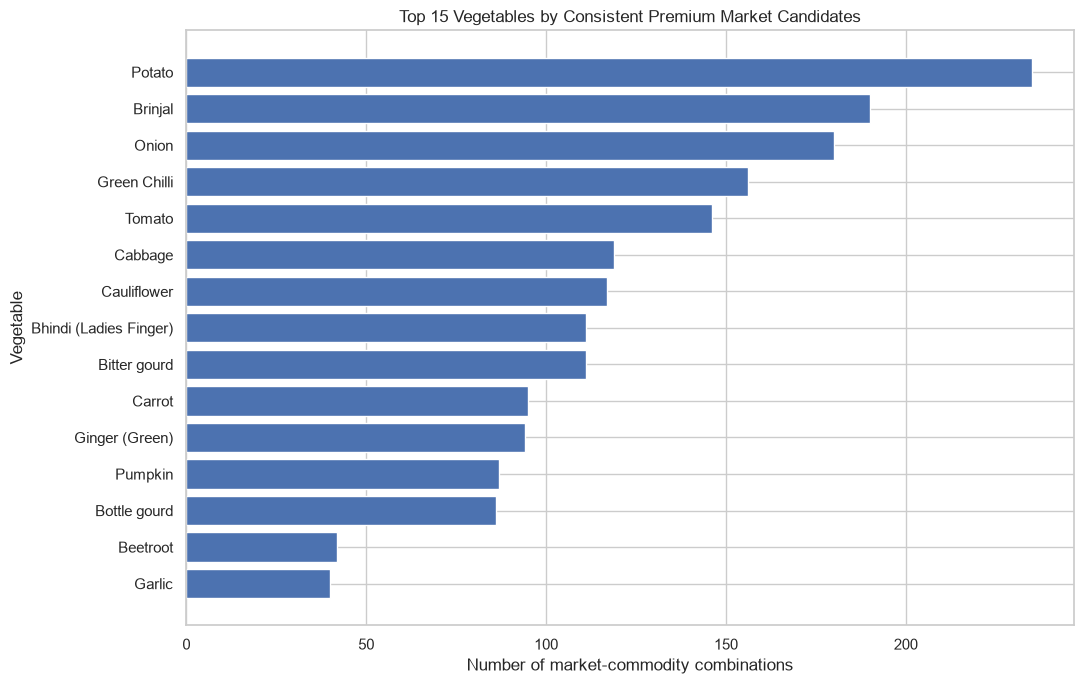

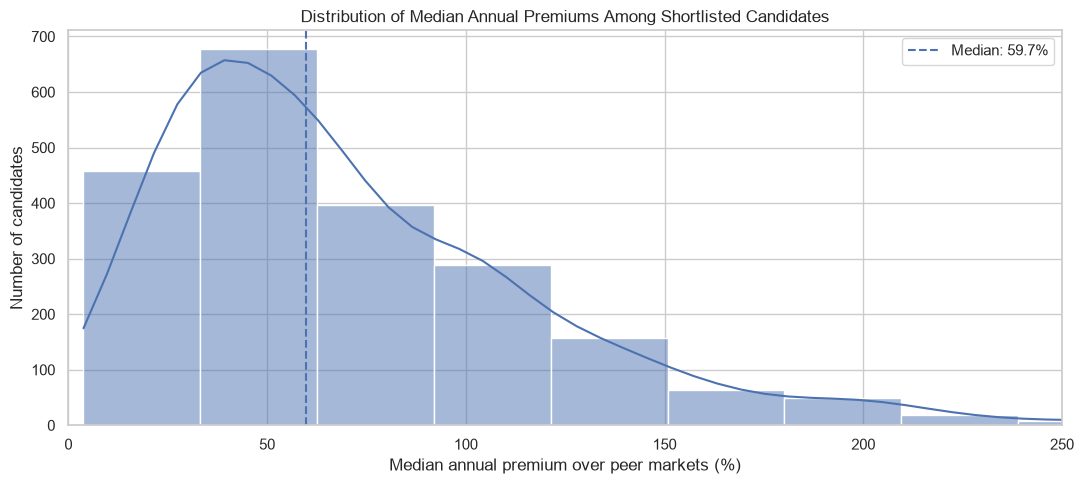

In [57]:
# Final visualizations for market comparison intelligence

# Chart 1: Commodities with the most shortlisted market combinations
top_commodities = (
    commodity_intelligence_summary
    .nlargest(15, "Candidate_Markets")
    .sort_values("Candidate_Markets")
)

plt.figure(figsize=(11, 7))
plt.barh(
    top_commodities["Commodity"],
    top_commodities["Candidate_Markets"]
)
plt.title("Top 15 Vegetables by Consistent Premium Market Candidates")
plt.xlabel("Number of market-commodity combinations")
plt.ylabel("Vegetable")
plt.tight_layout()
plt.show()


# Chart 2: Distribution of historical median annual premiums
plt.figure(figsize=(11, 5))
sns.histplot(
    stable_market_candidates["Median_Annual_Premium_Pct"],
    bins=40,
    kde=True
)

median_premium = stable_market_candidates[
    "Median_Annual_Premium_Pct"
].median()

plt.axvline(
    median_premium,
    linestyle="--",
    label=f"Median: {median_premium:.1f}%"
)

plt.xlim(0, 250)
plt.title("Distribution of Median Annual Premiums Among Shortlisted Candidates")
plt.xlabel("Median annual premium over peer markets (%)")
plt.ylabel("Number of candidates")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

# Inspect the existing Streamlit dataset and the new comparison view.
existing_file = OUTPUT_DIR / "market_comparison.parquet"

print("Existing file:", existing_file)
print("File exists:", existing_file.exists())

print("\nNEW comparison view schema:")
display(
    con.execute("""
        DESCRIBE
        SELECT * FROM market_premium_daily_reviewed
    """).df()
)

if existing_file.exists():
  print("\nEXISTING app dataset schema:")
  display(
      con.execute(
          f"DESCRIBE SELECT * FROM read_parquet('{existing_file.as_posix() }')"
      ).df()
  )

  # Evaluate count cleanly outside the print statement to avoid f-string nesting issues
  existing_count = con.execute(
      f"SELECT COUNT(*) FROM read_parquet('{existing_file.as_posix()}')"
  ).fetchone()[0]

  print("\nExisting dataset row count:")
  print(f"{existing_count:,}")

Existing file: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra\data\processed\market_comparison.parquet
File exists: True

NEW comparison view schema:


,column_name,column_type,null,key,default,extra
0,Commodity,VARCHAR,YES,None,None,None
1,Variety,VARCHAR,YES,None,None,None
2,Grade,VARCHAR,YES,None,None,None
3,Arrival_Date,DATE,YES,None,None,None
4,State,VARCHAR,YES,None,None,None
5,District,VARCHAR,YES,None,None,None
6,Market,VARCHAR,YES,None,None,None
7,Modal_Price,DOUBLE,YES,None,None,None
8,Source_Records,BIGINT,YES,None,None,None
9,Exclusion_Reason,VARCHAR,YES,None,None,None



EXISTING app dataset schema:


,column_name,column_type,null,key,default,extra
0,Commodity,VARCHAR,YES,None,None,None
1,Variety,VARCHAR,YES,None,None,None
2,Grade,VARCHAR,YES,None,None,None
3,Arrival_Date,DATE,YES,None,None,None
4,State,VARCHAR,YES,None,None,None
5,District,VARCHAR,YES,None,None,None
6,Market,VARCHAR,YES,None,None,None
7,Median_Modal_Price,DOUBLE,YES,None,None,None
8,Source_Records,BIGINT,YES,None,None,None
9,Peer_Median_Price,DOUBLE,YES,None,None,None



Existing dataset row count:
11,305,063


In [68]:
# Export reviewed market comparisons without touching the existing app file.

NEW_DATA_PATH = OUTPUT_DIR / "market_comparison_v2.parquet"

con.execute(f"""
    COPY (
        SELECT *
        FROM market_premium_daily_reviewed
        ORDER BY Commodity, Arrival_Date, State, District, Market
    )
    TO '{NEW_DATA_PATH.as_posix()}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Export completed:", NEW_DATA_PATH)
print("File size (MB):", round(NEW_DATA_PATH.stat().st_size / (1024 ** 2), 2))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Export completed: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra\data\processed\market_comparison_v2.parquet
File size (MB): 106.67


In [58]:
export_validation = con.execute(f"""
    SELECT
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT Commodity) AS Vegetables,
        COUNT(DISTINCT State || '|' || District || '|' || Market)
            AS Physical_Markets,
        MIN(Arrival_Date) AS First_Date,
        MAX(Arrival_Date) AS Last_Date,
        COUNT(*) FILTER (
            WHERE Peer_Market_Count < 3
        ) AS Invalid_Peer_Counts,
        COUNT(*) FILTER (
            WHERE Peer_Median_Price IS NULL
               OR Peer_Median_Price <= 0
        ) AS Invalid_Peer_Medians
    FROM read_parquet('{NEW_DATA_PATH.as_posix()}')
""").df()

display(export_validation)

NameError: name 'NEW_DATA_PATH' is not defined

In [59]:
# Inspect reporting frequency of each market series
# in the reviewed market-comparison dataset.

market_series_coverage = con.execute("""
    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,

        COUNT(*) AS Observation_Count,
        COUNT(DISTINCT Arrival_Date) AS Active_Days,

        MIN(Arrival_Date) AS First_Date,
        MAX(Arrival_Date) AS Last_Date,

        MEDIAN(Peer_Market_Count) AS Median_Peer_Count

    FROM market_premium_daily_reviewed

    GROUP BY
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade
""").df()

market_series_coverage["Date_Span_Days"] = (
    market_series_coverage["Last_Date"]
    - market_series_coverage["First_Date"]
).dt.days + 1

market_series_coverage["Reporting_Coverage_Pct"] = (
    100 * market_series_coverage["Active_Days"]
    / market_series_coverage["Date_Span_Days"]
)

display(
    market_series_coverage["Reporting_Coverage_Pct"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
    .to_frame("Reporting_Coverage_Pct")
)

print("Total market series:", len(market_series_coverage))
print("Total observations:", f"{market_series_coverage['Observation_Count'].sum():,}")

print("\nSeries meeting observation thresholds:")

for minimum in [100, 250, 500, 750, 1000]:
    count = (
        market_series_coverage["Observation_Count"] >= minimum
    ).sum()

    print(f"At least {minimum} observations: {count:,}")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Reporting_Coverage_Pct
count,"32,311.00"
mean,51.76
std,34.37
min,0.13
10%,5.20
25%,18.10
50%,52.58
75%,84.05
90%,100.00
max,100.00


Total market series: 32311
Total observations: 11,286,611

Series meeting observation thresholds:
At least 100 observations: 18,464
At least 250 observations: 14,199
At least 500 observations: 7,773
At least 750 observations: 5,551
At least 1000 observations: 3,712


In [60]:

# Measure future reporting coverage in rolling 7-calendar-day windows.
# Each observed market date is treated as a potential prediction date.
# Only observations strictly AFTER the prediction date are counted.

seven_day_coverage = con.execute("""
    WITH windowed AS (
        SELECT
            Commodity,
            State,
            District,
            Market,
            Variety,
            Grade,
            Arrival_Date,

            COUNT(*) OVER (
                PARTITION BY
                    Commodity,
                    State,
                    District,
                    Market,
                    Variety,
                    Grade
                ORDER BY Arrival_Date
                RANGE BETWEEN
                    INTERVAL 1 DAY FOLLOWING
                    AND INTERVAL 7 DAY FOLLOWING
            ) AS Future_Observations_7D

        FROM market_premium_daily_reviewed
    ),

    prediction_dates AS (
        SELECT *
        FROM windowed
        WHERE Arrival_Date <= DATE '2025-10-24'
    ),

    series_summary AS (
        SELECT
            Commodity,
            State,
            District,
            Market,
            Variety,
            Grade,

            COUNT(*) AS Prediction_Opportunities,

            AVG(
                CASE WHEN Future_Observations_7D >= 1
                     THEN 1.0 ELSE 0.0 END
            ) * 100 AS Pct_Windows_With_1_Observation,

            AVG(
                CASE WHEN Future_Observations_7D >= 3
                     THEN 1.0 ELSE 0.0 END
            ) * 100 AS Pct_Windows_With_3_Observations,

            AVG(
                CASE WHEN Future_Observations_7D >= 5
                     THEN 1.0 ELSE 0.0 END
            ) * 100 AS Pct_Windows_With_5_Observations

        FROM prediction_dates

        GROUP BY
            Commodity,
            State,
            District,
            Market,
            Variety,
            Grade
    )

    SELECT *
    FROM series_summary
""").df()

# Summarise coverage across market series.
coverage_metrics = [
    "Pct_Windows_With_1_Observation",
    "Pct_Windows_With_3_Observations",
    "Pct_Windows_With_5_Observations"
]

display(
    seven_day_coverage[coverage_metrics]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
    .T
)

print("Total market series:", len(seven_day_coverage))

print("\nSeries with sufficient prediction opportunities:")
for minimum in [30, 50, 100, 250]:
    count = (
        seven_day_coverage["Prediction_Opportunities"] >= minimum
    ).sum()
    print(f"At least {minimum} prediction dates: {count:,}")

print("\nSeries meeting future observation coverage thresholds:")
for threshold in [50, 60, 70, 80]:
    count = (
        seven_day_coverage[
            "Pct_Windows_With_3_Observations"
        ] >= threshold
    ).sum()
    print(
        f"At least 3 future observations in "
        f"{threshold}% of windows: {count:,}"
    )


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,count,mean,std,min,10%,25%,50%,75%,90%,max
Pct_Windows_With_1_Observation,"32,295.00",79.74,31.95,0.00,0.00,76.32,96.55,99.32,99.92,100.00
Pct_Windows_With_3_Observations,"32,295.00",62.68,39.11,0.00,0.00,20.83,83.86,95.80,99.17,100.00
Pct_Windows_With_5_Observations,"32,295.00",47.46,38.05,0.00,0.00,0.00,53.56,82.76,95.68,99.71


Total market series: 32295

Series with sufficient prediction opportunities:
At least 30 prediction dates: 22,428
At least 50 prediction dates: 20,821
At least 100 prediction dates: 18,461
At least 250 prediction dates: 14,186

Series meeting future observation coverage thresholds:
At least 3 future observations in 50% of windows: 21,802
At least 3 future observations in 60% of windows: 20,671
At least 3 future observations in 70% of windows: 19,242
At least 3 future observations in 80% of windows: 17,284


In [61]:
# Identify market series eligible for the relative-performance experiment

eligible_series = seven_day_coverage[
    (seven_day_coverage["Prediction_Opportunities"] >= 100) &
    (seven_day_coverage["Pct_Windows_With_3_Observations"] >= 70)
].copy()

strict_eligible_series = seven_day_coverage[
    (seven_day_coverage["Prediction_Opportunities"] >= 100) &
    (seven_day_coverage["Pct_Windows_With_3_Observations"] >= 80)
].copy()

print("Total market series:", len(seven_day_coverage))

print(
    "Eligible series (100 opportunities, 70% coverage):",
    len(eligible_series)
)

print(
    "Strict eligible series (100 opportunities, 80% coverage):",
    len(strict_eligible_series)
)

print("\nEligible series by commodity:")
display(
    eligible_series.groupby("Commodity")
    .size()
    .sort_values(ascending=False)
    .rename("Eligible_Series")
    .to_frame()
)

print("\nPrediction opportunity distribution:")
display(
    eligible_series["Prediction_Opportunities"].describe()
)

print("\nFuture observation coverage distribution:")
display(
    eligible_series["Pct_Windows_With_3_Observations"].describe()
)

Total market series: 32295
Eligible series (100 opportunities, 70% coverage): 16049
Strict eligible series (100 opportunities, 80% coverage): 14597

Eligible series by commodity:


,Eligible_Series
Commodity,
Potato,1325
Tomato,1301
Onion,1288
Brinjal,1057
Green Chilli,915
Bhindi (Ladies Finger),893
Cauliflower,850
Cabbage,802
Bitter gourd,715



Prediction opportunity distribution:


count   16,049.00
mean       641.50
std        403.93
min        100.00
25%        347.00
50%        460.00
75%        960.00
max      1,739.00
Name: Prediction_Opportunities, dtype: float64


Future observation coverage distribution:


count   16,049.00
mean        92.83
std          7.49
min         70.00
25%         89.08
50%         95.76
75%         98.76
max        100.00
Name: Pct_Windows_With_3_Observations, dtype: float64

In [62]:
# Examine geographic representation of eligible market series

# Count eligible series and represented states per commodity
commodity_coverage = (
    eligible_series
    .groupby("Commodity")
    .agg(
        Eligible_Series=("Market", "size"),
        States=("State", "nunique"),
        Districts=("District", "nunique")
    )
)

# Count distinct physical market identities per commodity
physical_market_counts = (
    eligible_series[
        ["Commodity", "State", "District", "Market"]
    ]
    .drop_duplicates()
    .groupby("Commodity")
    .size()
    .rename("Physical_Markets")
)

# Count stricter-threshold series
strict_counts = (
    strict_eligible_series
    .groupby("Commodity")
    .size()
    .rename("Strict_Eligible_Series")
)

commodity_coverage = (
    commodity_coverage
    .join(physical_market_counts)
    .join(strict_counts)
    .fillna(0)
    .astype(int)
    .sort_values("Eligible_Series", ascending=False)
)

display(commodity_coverage)

print("\nOverall geographic coverage")
print("Eligible series:", len(eligible_series))
print(
    "Distinct physical markets:",
    eligible_series[["State", "District", "Market"]]
    .drop_duplicates()
    .shape[0]
)
print("States:", eligible_series["State"].nunique())
print("Districts:", eligible_series["District"].nunique())

print("\nEligible series by state:")
display(
    eligible_series.groupby("State")
    .size()
    .sort_values(ascending=False)
    .rename("Eligible_Series")
    .to_frame()
)

,Eligible_Series,States,Districts,Physical_Markets,Strict_Eligible_Series
Commodity,,,,,
Potato,1325,27,385,1028,1211
Tomato,1301,26,388,1045,1208
Onion,1288,26,375,1032,1166
Brinjal,1057,26,357,958,975
Green Chilli,915,27,334,868,839
Bhindi (Ladies Finger),893,23,325,849,807
Cauliflower,850,27,328,789,776
Cabbage,802,26,323,758,728
Bitter gourd,715,23,276,678,653



Overall geographic coverage
Eligible series: 16049
Distinct physical markets: 1411
States: 28
Districts: 444

Eligible series by state:


,Eligible_Series
State,
Tamil Nadu,3790
Uttar Pradesh,2779
Kerala,1410
Punjab,1220
Maharashtra,1135
Madhya Pradesh,808
Haryana,793
West Bengal,599
Odisha,454


In [63]:
# Select candidate market series using data available before 2024

historical_cutoff = "2023-12-31"

historical_eligibility = con.execute(f"""
    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        COUNT(*) AS Historical_Observations,
        COUNT(DISTINCT Arrival_Date) AS Historical_Active_Days,
        MIN(Arrival_Date) AS Historical_First_Date,
        MAX(Arrival_Date) AS Historical_Last_Date
    FROM market_premium_daily_reviewed
    WHERE Arrival_Date <= DATE '{historical_cutoff}'
    GROUP BY
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade
""").df()

historical_eligible_series = historical_eligibility[
    historical_eligibility["Historical_Observations"] >= 100
].copy()

print("Total historical market series:", len(historical_eligibility))

print(
    "Series with at least 100 historical observations:",
    len(historical_eligible_series)
)

print("\nHistorical observation distribution:")
display(
    historical_eligible_series["Historical_Observations"].describe()
)

print("\nEligible series by commodity:")
display(
    historical_eligible_series.groupby("Commodity")
    .size()
    .sort_values(ascending=False)
    .rename("Historical_Eligible_Series")
    .to_frame()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Total historical market series: 18472
Series with at least 100 historical observations: 11527

Historical observation distribution:


count   11,527.00
mean       495.16
std        270.80
min        100.00
25%        244.00
50%        472.00
75%        738.00
max      1,087.00
Name: Historical_Observations, dtype: float64


Eligible series by commodity:


,Historical_Eligible_Series
Commodity,
Potato,1027
Onion,988
Tomato,958
Brinjal,864
Green Chilli,735
Cauliflower,692
Bhindi (Ladies Finger),675
Cabbage,630
Bitter gourd,544


In [64]:
# Measure future target availability for historically eligible series

historical_keys = historical_eligible_series[
    ["Commodity", "State", "District", "Market", "Variety", "Grade"]
].copy()

historical_keys["Eligible"] = True

future_availability = con.execute("""
    WITH future_windows AS (
        SELECT
            Commodity,
            State,
            District,
            Market,
            Variety,
            Grade,
            Arrival_Date,
            COUNT(*) OVER (
                PARTITION BY Commodity, State, District, Market, Variety, Grade
                ORDER BY Arrival_Date
                RANGE BETWEEN
                    INTERVAL 1 DAY FOLLOWING
                    AND INTERVAL 7 DAY FOLLOWING
            ) AS Future_Observations_7D
        FROM market_premium_daily_reviewed
        WHERE Arrival_Date >= DATE '2024-01-01'
          AND Arrival_Date <= DATE '2025-10-24'
    )
    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        COUNT(*) AS Future_Prediction_Dates,
        AVG(
            CASE WHEN Future_Observations_7D >= 3
                 THEN 1.0 ELSE 0.0 END
        ) * 100 AS Pct_Windows_With_3_Future_Observations
    FROM future_windows
    GROUP BY
        Commodity, State, District, Market, Variety, Grade
""").df()

# Restrict future results to series eligible before 2024
future_eligible = future_availability.merge(
    historical_keys,
    on=["Commodity", "State", "District", "Market", "Variety", "Grade"],
    how="inner"
)

print("Historically eligible series:", len(historical_eligible_series))
print("With at least one future prediction date:", len(future_eligible))

print("\nFuture prediction date distribution:")
display(future_eligible["Future_Prediction_Dates"].describe())

print("\nFuture observation coverage distribution:")
display(
    future_eligible[
        "Pct_Windows_With_3_Future_Observations"
    ].describe()
)

print("\nSeries by future prediction opportunities:")
for threshold in [30, 50, 100, 150]:
    print(
        f"At least {threshold} future prediction dates:",
        (
            future_eligible["Future_Prediction_Dates"] >= threshold
        ).sum()
    )

print("\nSeries with sufficient future observation coverage:")
for threshold in [50, 60, 70, 80]:
    print(
        f"At least {threshold}% of windows have 3 observations:",
        (
            future_eligible[
                "Pct_Windows_With_3_Future_Observations"
            ] >= threshold
        ).sum()
    )

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Historically eligible series: 11527
With at least one future prediction date: 9914

Future prediction date distribution:


count   9,914.00
mean      303.07
std       178.89
min         1.00
25%       148.00
50%       304.00
75%       463.00
max       659.00
Name: Future_Prediction_Dates, dtype: float64


Future observation coverage distribution:


count   9,914.00
mean       79.21
std        27.65
min         0.00
25%        74.19
50%        91.89
75%        97.23
max        99.54
Name: Pct_Windows_With_3_Future_Observations, dtype: float64


Series by future prediction opportunities:
At least 30 future prediction dates: 9268
At least 50 future prediction dates: 8989
At least 100 future prediction dates: 8214
At least 150 future prediction dates: 7419

Series with sufficient future observation coverage:
At least 50% of windows have 3 observations: 8572
At least 60% of windows have 3 observations: 8207
At least 70% of windows have 3 observations: 7727
At least 80% of windows have 3 observations: 6890


In [65]:
# Inspect future peer-relative premium distribution

future_target_audit = con.execute("""
    SELECT
        Commodity,
        COUNT(*) AS Observations,
        COUNT(DISTINCT Arrival_Date) AS Active_Dates,
        MEDIAN(Premium_Discount_Pct) AS Median_Premium_Pct,
        AVG(Premium_Discount_Pct) AS Mean_Premium_Pct,
        QUANTILE_CONT(Premium_Discount_Pct, 0.10) AS P10_Premium_Pct,
        QUANTILE_CONT(Premium_Discount_Pct, 0.90) AS P90_Premium_Pct,
        QUANTILE_CONT(ABS(Premium_Discount_Pct), 0.95) AS P95_Absolute_Premium_Pct,
        MIN(Premium_Discount_Pct) AS Minimum_Premium_Pct,
        MAX(Premium_Discount_Pct) AS Maximum_Premium_Pct
    FROM market_premium_daily_reviewed
    WHERE Arrival_Date BETWEEN DATE '2024-01-01'
                           AND DATE '2025-10-31'
    GROUP BY Commodity
    ORDER BY Observations DESC
""").df()

display(future_target_audit)

print("\nOverall future premium distribution:")
display(
    con.execute("""
        SELECT
            COUNT(*) AS Observations,
            MEDIAN(Premium_Discount_Pct) AS Median,
            AVG(Premium_Discount_Pct) AS Mean,
            STDDEV(Premium_Discount_Pct) AS Std_Dev,
            QUANTILE_CONT(Premium_Discount_Pct, 0.01) AS P01,
            QUANTILE_CONT(Premium_Discount_Pct, 0.05) AS P05,
            QUANTILE_CONT(Premium_Discount_Pct, 0.95) AS P95,
            QUANTILE_CONT(Premium_Discount_Pct, 0.99) AS P99
        FROM market_premium_daily_reviewed
        WHERE Arrival_Date BETWEEN DATE '2024-01-01'
                               AND DATE '2025-10-31'
    """).df()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Observations,Active_Dates,Median_Premium_Pct,Mean_Premium_Pct,P10_Premium_Pct,P90_Premium_Pct,P95_Absolute_Premium_Pct,Minimum_Premium_Pct,Maximum_Premium_Pct
0,Onion,430284,670,0.00,74.70,-30.00,33.33,63.89,-99.64,"30,791,459.83"
1,Tomato,418655,670,0.00,8.45,-38.46,60.00,96.08,-99.75,"14,862.96"
2,Potato,411594,670,0.00,12.30,-30.00,68.89,119.51,-98.92,"1,926.32"
3,Brinjal,375115,670,0.00,18.57,-45.24,105.88,150.00,-99.19,"32,400.00"
4,Green Chilli,343703,670,0.00,17.42,-39.13,87.50,138.41,-98.66,"96,253.21"
5,Bhindi (Ladies Finger),283969,670,0.00,12.27,-37.50,75.00,112.77,-98.60,"14,700.00"
6,Cabbage,257965,670,0.00,17.91,-44.44,100.00,165.18,-98.33,"16,566.67"
7,Bottle gourd,257830,670,0.00,9.08,-41.67,67.77,105.13,-99.51,"18,175.00"
8,Cauliflower,247372,670,0.00,17.16,-45.88,92.59,154.55,-99.44,"9,900.00"
9,Bitter gourd,240804,670,0.00,14.06,-42.22,89.23,132.26,-99.69,"1,313.04"



Overall future premium distribution:


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Observations,Median,Mean,Std_Dev,P01,P05,P95,P99
0,5388095,0.00,21.25,"13,271.03",-71.29,-50.18,111.11,240.00


In [66]:
# Investigate extreme peer-relative premiums

extreme_premiums = con.execute("""
    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        Arrival_Date,
        Modal_Price,
        Peer_Median_Price,
        Peer_Market_Count,
        Premium_Discount_Pct,
        Modal_Price / NULLIF(Peer_Median_Price, 0)
            AS Market_To_Peer_Ratio
    FROM market_premium_daily_reviewed
    WHERE Arrival_Date BETWEEN DATE '2024-01-01'
                           AND DATE '2025-10-31'
    ORDER BY ABS(Premium_Discount_Pct) DESC
    LIMIT 100
""").df()

display(extreme_premiums)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,State,District,Market,Variety,Grade,Arrival_Date,Modal_Price,Peer_Median_Price,Peer_Market_Count,Premium_Discount_Pct,Market_To_Peer_Ratio
0,Onion,Maharashtra,Nashik,Kalvan,Red,FAQ,2024-12-23,"917,588,483.00","2,980.00",183,"30,791,459.83","307,915.60"
1,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),Other,FAQ,2024-10-06,"5,800.00",4.00,3,"144,900.00","1,450.00"
2,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),Other,FAQ,2024-10-03,"5,800.00",5.00,3,"115,900.00","1,160.00"
3,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),Other,FAQ,2024-09-05,"6,800.00",6.00,4,"113,233.33","1,133.33"
4,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),Other,FAQ,2024-09-04,"6,800.00",6.00,3,"113,233.33","1,133.33"
5,Mint (Pudina),Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),Other,FAQ,2024-12-08,"5,500.00",5.00,3,"109,900.00","1,100.00"
6,Mint (Pudina),Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),Other,FAQ,2024-10-06,"4,200.00",4.00,3,"104,900.00","1,050.00"
7,Mint (Pudina),Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),Other,FAQ,2024-12-15,"5,200.00",5.00,3,"103,900.00","1,040.00"
8,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),Other,FAQ,2024-07-14,"5,800.00",6.00,3,"96,566.67",966.67
9,Green Chilli,Kerala,Kollam,Valakom VFPCK,Green Chilly,FAQ,2024-07-05,"3,950,000.00","4,099.50",324,"96,253.21",963.53


In [67]:
low_peer_price_audit = con.execute("""
    SELECT
        Commodity,
        COUNT(*) AS Total_Observations,

        COUNT(*) FILTER (
            WHERE Peer_Median_Price < 10
        ) AS Peer_Below_10,

        COUNT(*) FILTER (
            WHERE Peer_Median_Price < 50
        ) AS Peer_Below_50,

        COUNT(*) FILTER (
            WHERE Peer_Median_Price < 100
        ) AS Peer_Below_100,

        MEDIAN(Peer_Median_Price) AS Median_Peer_Price,
        MEDIAN(Modal_Price) AS Median_Market_Price,

        MAX(Peer_Median_Price) AS Max_Peer_Price,
        MAX(Modal_Price) AS Max_Market_Price

    FROM market_premium_daily_reviewed
    WHERE Arrival_Date BETWEEN DATE '2024-01-01'
                           AND DATE '2025-10-31'
    GROUP BY Commodity
    ORDER BY Peer_Below_10 DESC
""").df()

display(low_peer_price_audit)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Total_Observations,Peer_Below_10,Peer_Below_50,Peer_Below_100,Median_Peer_Price,Median_Market_Price,Max_Peer_Price,Max_Market_Price
0,Mint (Pudina),75465,403,465,2123,"4,000.00","4,000.00","9,500.00","50,000.00"
1,Spinach,51174,143,452,482,"1,100.00","1,150.00","4,525.00","13,000.00"
2,Onion Green,84052,52,812,2551,"5,000.00","5,000.00","9,000.00","63,000.00"
3,Methi (Leaves),22377,13,186,191,"1,200.00","1,200.00","8,000.00","18,000.00"
4,Drumstick,108100,0,0,121,"6,000.00","6,000.00","34,900.00","180,000.00"
5,Capsicum,116386,0,0,501,"4,580.00","4,500.00","8,300.00","60,100.00"
6,Cauliflower,247372,0,895,1082,"2,230.00","2,400.00","9,500.00","250,000.00"
7,Duster Beans,56,0,0,0,"6,100.00","6,100.00","9,100.00","10,000.00"
8,Elephant Yam (Suran),63009,0,0,976,"6,000.00","6,000.00","8,600.00","90,000.00"
9,Sweet Potato,41379,0,423,423,"4,000.00","4,000.00","7,600.00","13,000.00"


In [68]:
low_peer_examples = con.execute("""
    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        Arrival_Date,
        Modal_Price,
        Peer_Median_Price,
        Peer_Market_Count,
        Premium_Discount_Pct
    FROM market_premium_daily_reviewed
    WHERE Arrival_Date BETWEEN DATE '2024-01-01'
                           AND DATE '2025-10-31'
      AND Peer_Median_Price < 100
    ORDER BY
        Commodity,
        Peer_Median_Price,
        ABS(Premium_Discount_Pct) DESC
    LIMIT 100
""").df()

display(low_peer_examples)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,State,District,Market,Variety,Grade,Arrival_Date,Modal_Price,Peer_Median_Price,Peer_Market_Count,Premium_Discount_Pct
0,Amaranthus,Tamil Nadu,Krishnagiri,Denkanikottai,Amaranthus,Local,2024-07-06,80.00,25.00,84,220.00
1,Amaranthus,Tamil Nadu,Krishnagiri,Denkanikottai,Amaranthus,Local,2024-07-04,80.00,25.00,84,220.00
2,Amaranthus,Tamil Nadu,Krishnagiri,Denkanikottai,Amaranthus,Local,2024-06-20,80.00,25.00,84,220.00
3,Amaranthus,Tamil Nadu,Krishnagiri,Denkanikottai,Amaranthus,Local,2024-06-29,80.00,25.00,83,220.00
4,Amaranthus,Tamil Nadu,Krishnagiri,Denkanikottai,Amaranthus,Local,2024-06-22,80.00,25.00,84,220.00
5,Amaranthus,Tamil Nadu,Krishnagiri,Hosur,Amaranthus,Local,2024-06-18,80.00,25.00,84,220.00
6,Amaranthus,Tamil Nadu,Krishnagiri,Hosur,Amaranthus,Local,2024-06-22,80.00,25.00,84,220.00
7,Amaranthus,Tamil Nadu,Krishnagiri,Hosur,Amaranthus,Local,2024-06-30,80.00,25.00,83,220.00
8,Amaranthus,Tamil Nadu,Krishnagiri,Hosur,Amaranthus,Local,2024-06-28,80.00,25.00,83,220.00
9,Amaranthus,Tamil Nadu,Krishnagiri,Hosur,Amaranthus,Local,2024-06-23,80.00,25.00,84,220.00


In [69]:
amaranthus_peer_audit = con.execute("""
    SELECT
        State,
        District,
        Market,
        Modal_Price,
        Peer_Median_Price,
        Peer_Market_Count,
        Premium_Discount_Pct
    FROM market_premium_daily_reviewed
    WHERE Commodity = 'Amaranthus'
      AND Variety = 'Amaranthus'
      AND Grade = 'Local'
      AND Arrival_Date = DATE '2024-06-20'
    ORDER BY Modal_Price
""").df()

display(amaranthus_peer_audit)

print("Number of reporting markets:", len(amaranthus_peer_audit))
print("\nPrice distribution:")
display(
    amaranthus_peer_audit["Modal_Price"].describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
    )
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,District,Market,Modal_Price,Peer_Median_Price,Peer_Market_Count,Premium_Discount_Pct
0,Tamil Nadu,Virudhunagar,Virudhunagar,10.00,25.50,84,-60.78
1,Tamil Nadu,Thiruvarur,Valangaiman,10.00,25.50,84,-60.78
2,Tamil Nadu,Nagercoil (Kannyiakumari),Vadaseri,10.00,25.50,84,-60.78
3,Tamil Nadu,Thiruvarur,Tiruthuraipoondi,10.00,25.50,84,-60.78
4,Tamil Nadu,Tuticorin,Thoothukudi,10.00,25.50,84,-60.78
5,Tamil Nadu,Coimbatore,Palladam,10.00,25.50,84,-60.78
6,Tamil Nadu,Pudukkottai,Alangudi,15.00,25.50,84,-41.18
7,Tamil Nadu,Nagapattinam,Nagapattinam,15.00,25.50,84,-41.18
8,Tamil Nadu,Thiruchirappalli,Manachanallur,15.00,25.50,84,-41.18
9,Tamil Nadu,Nagapattinam,Mailaduthurai,15.00,25.50,84,-41.18


Number of reporting markets: 85

Price distribution:


count   85.00
mean    27.32
std     12.66
min     10.00
10%     15.00
25%     20.00
50%     25.00
75%     35.00
90%     40.00
max     80.00
Name: Modal_Price, dtype: float64

In [70]:
mint_peer_audit = con.execute("""
    SELECT
        Commodity,
        Variety,
        Grade,
        Arrival_Date,
        State,
        District,
        Market,
        Modal_Price,
        Peer_Median_Price,
        Peer_Market_Count,
        Premium_Discount_Pct
    FROM market_premium_daily_reviewed
    WHERE
        Commodity ILIKE '%mint%'
        AND State = 'Gujarat'
        AND District = 'Vadodara'
        AND Market ILIKE '%Sayajipura%'
        AND Arrival_Date BETWEEN DATE '2024-01-01'
                             AND DATE '2025-10-31'
    ORDER BY Arrival_Date
""").df()

display(mint_peer_audit)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Variety,Grade,Arrival_Date,State,District,Market,Modal_Price,Peer_Median_Price,Peer_Market_Count,Premium_Discount_Pct


In [71]:
sayajipura_audit = con.execute("""
    SELECT
        Commodity,
        Variety,
        Grade,
        Arrival_Date,
        State,
        District,
        Market,
        Modal_Price,
        Peer_Median_Price,
        Peer_Market_Count,
        Premium_Discount_Pct
    FROM market_premium_daily_reviewed
    WHERE
        Market ILIKE '%Sayajipura%'
        AND Arrival_Date BETWEEN DATE '2024-01-01'
                             AND DATE '2025-10-31'
    ORDER BY ABS(Premium_Discount_Pct) DESC
    LIMIT 100
""").df()

display(sayajipura_audit)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Variety,Grade,Arrival_Date,State,District,Market,Modal_Price,Peer_Median_Price,Peer_Market_Count,Premium_Discount_Pct
0,Mint (Pudina),Other,FAQ,2024-10-06,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"5,800.00",4.00,3,"144,900.00"
1,Mint (Pudina),Other,FAQ,2024-10-03,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"5,800.00",5.00,3,"115,900.00"
2,Mint (Pudina),Other,FAQ,2024-09-05,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"6,800.00",6.00,4,"113,233.33"
3,Mint (Pudina),Other,FAQ,2024-09-04,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"6,800.00",6.00,3,"113,233.33"
4,Mint (Pudina),Other,FAQ,2024-07-14,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"5,800.00",6.00,3,"96,566.67"
5,Mint (Pudina),Other,FAQ,2024-09-22,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"5,900.00",6.50,4,"90,669.23"
6,Mint (Pudina),Other,FAQ,2024-09-09,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"6,800.00",8.00,5,"84,900.00"
7,Mint (Pudina),Other,FAQ,2024-09-06,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"6,800.00",8.00,4,"84,900.00"
8,Mint (Pudina),Other,FAQ,2024-07-11,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"5,800.00",7.00,7,"82,757.14"
9,Mint (Pudina),Other,FAQ,2024-07-13,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"5,800.00",7.00,5,"82,757.14"


In [72]:
mint_peer_detail = con.execute("""
    SELECT
        State,
        District,
        Market,
        Modal_Price,
        Peer_Median_Price,
        Peer_Market_Count,
        Premium_Discount_Pct
    FROM market_premium_daily_reviewed
    WHERE Commodity = 'Mint (Pudina)'
      AND Variety = 'Other'
      AND Grade = 'FAQ'
      AND Arrival_Date = DATE '2024-10-06'
    ORDER BY Modal_Price
""").df()

display(mint_peer_detail)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,District,Market,Modal_Price,Peer_Median_Price,Peer_Market_Count,Premium_Discount_Pct
0,Maharashtra,Pune,Pune,3.00,"4,200.00",3,-99.93
1,Maharashtra,Pune,Pune (Moshi),4.00,"4,200.00",3,-99.90
2,Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),"4,200.00",4.00,3,"104,900.00"
3,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"5,800.00",4.00,3,"144,900.00"


In [73]:
mint_source_check = con.execute("""
    SELECT *
    FROM market_day_prices_reviewed
    WHERE Commodity = 'Mint (Pudina)'
      AND Variety = 'Other'
      AND Grade = 'FAQ'
      AND Arrival_Date = DATE '2024-10-06'
    ORDER BY Modal_Price
""").df()

display(mint_source_check)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Variety,Grade,Arrival_Date,State,District,Market,Modal_Price,Source_Records,Exclusion_Reason
0,Mint (Pudina),Other,FAQ,2024-10-06,Maharashtra,Pune,Pune,3.00,1,None
1,Mint (Pudina),Other,FAQ,2024-10-06,Maharashtra,Pune,Pune (Moshi),4.00,1,None
2,Mint (Pudina),Other,FAQ,2024-10-06,Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),"4,200.00",1,None
3,Mint (Pudina),Other,FAQ,2024-10-06,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),"5,800.00",1,None


In [74]:
mint_market_scale_audit = con.execute("""
    SELECT
        State,
        District,
        Market,
        COUNT(*) AS Observation_Count,
        MEDIAN(Modal_Price) AS Median_Price,
        QUANTILE_CONT(Modal_Price, 0.10) AS P10_Price,
        QUANTILE_CONT(Modal_Price, 0.90) AS P90_Price,
        MIN(Modal_Price) AS Min_Price,
        MAX(Modal_Price) AS Max_Price,
        MIN(Arrival_Date) AS First_Date,
        MAX(Arrival_Date) AS Last_Date
    FROM market_day_prices_reviewed
    WHERE Commodity = 'Mint (Pudina)'
      AND Variety = 'Other'
      AND Grade = 'FAQ'
      AND Arrival_Date BETWEEN DATE '2021-01-01'
                           AND DATE '2025-10-31'
    GROUP BY State, District, Market
    ORDER BY Median_Price
""").df()

display(mint_market_scale_audit)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,District,Market,Observation_Count,Median_Price,P10_Price,P90_Price,Min_Price,Max_Price,First_Date,Last_Date
0,Maharashtra,Pune,Pune (Manjri),498,2.00,2.00,6.00,1.00,10.00,2021-01-17,2025-01-07
1,Maharashtra,Pune,Pune,1161,3.00,2.00,5.00,1.00,650.00,2021-01-01,2025-01-24
2,Maharashtra,Pune,Pune (Khadiki),145,3.00,2.00,5.00,2.00,7.00,2021-01-23,2024-07-06
3,Maharashtra,Pune,Pune (Moshi),1165,4.00,3.00,5.00,2.00,45.00,2021-01-01,2025-01-25
4,Maharashtra,Pune,Pune (Pimpri),905,4.00,3.00,6.00,2.00,8.00,2021-01-04,2024-11-25
5,Maharashtra,Ahmednagar,Rahata,123,9.00,5.00,10.00,3.00,15.00,2021-02-16,2025-01-26
6,Maharashtra,Nashik,Nasik,88,150.00,150.00,230.00,14.00,"4,500.00",2021-01-01,2024-12-17
7,Maharashtra,Nashik,Nashik (Devlali),6,525.00,275.00,"1,350.00",250.00,"1,500.00",2021-01-01,2024-12-31
8,Maharashtra,Mumbai,Mumbai,1114,550.00,350.00,900.00,250.00,"2,200.00",2021-01-01,2025-01-24
9,Punjab,Jalandhar,Phillaur,7,800.00,800.00,"1,600.00",800.00,"2,500.00",2023-05-04,2023-08-31


In [75]:
market_cross_commodity_audit = con.execute("""
    SELECT
        Commodity,
        State,
        District,
        Market,
        COUNT(*) AS Observation_Count,
        MEDIAN(Modal_Price) AS Median_Price,
        QUANTILE_CONT(Modal_Price, 0.10) AS P10_Price,
        QUANTILE_CONT(Modal_Price, 0.90) AS P90_Price
    FROM market_day_prices_reviewed
    WHERE
        (
            (State = 'Maharashtra' AND District = 'Pune'
                AND Market IN ('Pune', 'Pune (Moshi)'))
            OR
            (State = 'Gujarat' AND District = 'Vadodara (Baroda)'
                AND Market = 'Vadodara (Sayajipura)')
            OR
            (State = 'Rajasthan' AND District = 'Jodhpur'
                AND Market = 'Jodhpur (F&V)(Paota)')
        )
        AND Arrival_Date BETWEEN DATE '2021-01-01'
                             AND DATE '2025-10-31'
    GROUP BY Commodity, State, District, Market
    HAVING COUNT(*) >= 30
    ORDER BY Commodity, State, District, Market
""").df()

display(market_cross_commodity_audit)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,State,District,Market,Observation_Count,Median_Price,P10_Price,P90_Price
0,Beans,Maharashtra,Pune,Pune,1377,"4,000.00","2,500.00","6,500.00"
1,Beans,Maharashtra,Pune,Pune (Moshi),1402,"3,500.00","2,500.00","5,500.00"
2,Beetroot,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),1206,"1,800.00","1,150.00","2,450.00"
3,Beetroot,Maharashtra,Pune,Pune,1370,"1,250.00",750.00,"1,750.00"
4,Beetroot,Maharashtra,Pune,Pune (Moshi),1393,"1,500.00",900.00,"2,500.00"
5,Beetroot,Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),589,"2,000.00","1,400.00","2,500.00"
6,Bhindi (Ladies Finger),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),1190,"2,500.00","1,300.00","4,300.00"
7,Bhindi (Ladies Finger),Maharashtra,Pune,Pune,1389,"3,000.00","2,000.00","4,250.00"
8,Bhindi (Ladies Finger),Maharashtra,Pune,Pune (Moshi),1413,"3,000.00","2,100.00","4,500.00"
9,Bhindi (Ladies Finger),Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),1498,"2,500.00","1,500.00","4,000.00"


In [81]:
raw_schema = con.execute("""
    DESCRIBE
    SELECT *
    FROM read_parquet(?)
""", [str(cleaned_file)]).df()

display(raw_schema)

,column_name,column_type,null,key,default,extra
0,State,VARCHAR,YES,None,None,None
1,District,VARCHAR,YES,None,None,None
2,Market,VARCHAR,YES,None,None,None
3,Source_Commodity,VARCHAR,YES,None,None,None
4,Project_Commodity,VARCHAR,YES,None,None,None
5,Variety,VARCHAR,YES,None,None,None
6,Grade,VARCHAR,YES,None,None,None
7,Arrival_Date,VARCHAR,YES,None,None,None
8,Parsed_Date,DATE,YES,None,None,None
9,Min_Price,DOUBLE,YES,None,None,None


In [82]:
mint_source_audit = con.execute("""
    SELECT
        State,
        District,
        Market,
        Source_Commodity,
        Project_Commodity,
        Variety,
        Grade,
        Min_Price,
        Max_Price,
        Modal_Price
    FROM read_parquet(?)
    WHERE Project_Commodity = 'Mint (Pudina)'
      AND Variety = 'Other'
      AND Grade = 'FAQ'
      AND Parsed_Date = DATE '2024-10-06'
      AND (
          (State = 'Maharashtra' AND District = 'Pune')
          OR
          (State = 'Rajasthan' AND District = 'Jodhpur')
          OR
          (State = 'Gujarat' AND District = 'Vadodara (Baroda)')
      )
    ORDER BY Modal_Price
""", [str(cleaned_file)]).df()

display(mint_source_audit)

,State,District,Market,Source_Commodity,Project_Commodity,Variety,Grade,Min_Price,Max_Price,Modal_Price
0,Maharashtra,Pune,Pune,Mint (Pudina),Mint (Pudina),Other,FAQ,2.00,5.00,3.00
1,Maharashtra,Pune,Pune (Moshi),Mint (Pudina),Mint (Pudina),Other,FAQ,3.00,5.00,4.00
2,Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),Mint (Pudina),Mint (Pudina),Other,FAQ,"4,000.00","4,500.00","4,200.00"
3,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),Mint (Pudina),Mint (Pudina),Other,FAQ,"5,500.00","6,000.00","5,800.00"


In [83]:
mint_annual_scale_audit = con.execute("""
    SELECT
        State,
        District,
        Market,
        YEAR(Parsed_Date) AS Year,
        COUNT(*) AS Observation_Count,
        MEDIAN(Modal_Price) AS Median_Price,
        QUANTILE_CONT(Modal_Price, 0.10) AS P10_Price,
        QUANTILE_CONT(Modal_Price, 0.90) AS P90_Price,
        MIN(Modal_Price) AS Min_Price,
        MAX(Modal_Price) AS Max_Price
    FROM read_parquet(?)
    WHERE Project_Commodity = 'Mint (Pudina)'
      AND Variety = 'Other'
      AND Grade = 'FAQ'
      AND Parsed_Date BETWEEN DATE '2021-01-01'
                          AND DATE '2025-10-31'
      AND (
          (State = 'Maharashtra' AND District = 'Pune'
              AND Market IN ('Pune', 'Pune (Moshi)'))
          OR
          (State = 'Rajasthan' AND District = 'Jodhpur'
              AND Market = 'Jodhpur (F&V)(Paota)')
          OR
          (State = 'Gujarat' AND District = 'Vadodara (Baroda)'
              AND Market = 'Vadodara (Sayajipura)')
      )
    GROUP BY State, District, Market, Year
    ORDER BY Year, State, District, Market
""", [str(cleaned_file)]).df()

display(mint_annual_scale_audit)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,District,Market,Year,Observation_Count,Median_Price,P10_Price,P90_Price,Min_Price,Max_Price
0,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),2021,267,"1,800.00","1,400.00","2,950.00",900.00,"3,800.00"
1,Maharashtra,Pune,Pune,2021,285,2.00,1.00,3.00,1.00,5.00
2,Maharashtra,Pune,Pune (Moshi),2021,278,3.00,3.00,4.00,2.00,30.00
3,Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),2021,106,800.00,500.00,"1,500.00",400.00,"2,500.00"
4,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),2022,226,"1,950.00","1,450.00","3,800.00",700.00,"5,800.00"
5,Maharashtra,Pune,Pune,2022,275,3.00,2.00,6.00,1.00,9.00
6,Maharashtra,Pune,Pune (Moshi),2022,284,4.00,3.00,6.00,2.00,45.00
7,Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),2022,323,"1,100.00",900.00,"1,400.00",500.00,"1,800.00"
8,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),2023,258,"1,950.00","1,450.00","3,900.00",650.00,"4,800.00"
9,Maharashtra,Pune,Pune,2023,285,3.00,3.00,4.00,1.00,19.00


In [84]:
leafy_market_audit = con.execute("""
    SELECT
        Project_Commodity,
        State,
        District,
        Market,
        COUNT(*) AS Observation_Count,
        MEDIAN(Modal_Price) AS Median_Price,
        QUANTILE_CONT(Modal_Price, 0.10) AS P10_Price,
        QUANTILE_CONT(Modal_Price, 0.90) AS P90_Price
    FROM read_parquet(?)
    WHERE Project_Commodity IN (
        'Mint (Pudina)',
        'Methi (Leaves)',
        'Spinach',
        'Onion Green',
        'Coriander (Leaves)'
    )
      AND Parsed_Date BETWEEN DATE '2021-01-01'
                          AND DATE '2025-10-31'
      AND (
          (State = 'Maharashtra' AND District = 'Pune'
              AND Market IN ('Pune', 'Pune (Moshi)'))
          OR
          (State = 'Rajasthan' AND District = 'Jodhpur'
              AND Market = 'Jodhpur (F&V)(Paota)')
          OR
          (State = 'Gujarat' AND District = 'Vadodara (Baroda)'
              AND Market = 'Vadodara (Sayajipura)')
      )
    GROUP BY Project_Commodity, State, District, Market
    HAVING COUNT(*) >= 30
    ORDER BY Project_Commodity, Market
""", [str(cleaned_file)]).df()

display(leafy_market_audit)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,State,District,Market,Observation_Count,Median_Price,P10_Price,P90_Price
0,Methi (Leaves),Maharashtra,Pune,Pune,1323,9.00,5.00,16.00
1,Methi (Leaves),Maharashtra,Pune,Pune (Moshi),1402,10.00,6.00,20.00
2,Methi (Leaves),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),1175,"2,900.00",950.00,"7,800.00"
3,Mint (Pudina),Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),1269,"1,200.00",800.00,"3,500.00"
4,Mint (Pudina),Maharashtra,Pune,Pune,1375,3.00,2.00,5.00
5,Mint (Pudina),Maharashtra,Pune,Pune (Moshi),1383,4.00,3.00,6.00
6,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),1170,"2,400.00","1,450.00","3,905.00"
7,Onion Green,Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),776,800.00,400.00,"1,500.00"
8,Onion Green,Maharashtra,Pune,Pune,1370,9.00,6.00,13.00
9,Onion Green,Maharashtra,Pune,Pune (Moshi),1391,11.00,7.00,18.00


In [85]:
series_scale_audit = con.execute("""
    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        COUNT(*) AS Observation_Count,
        MEDIAN(Modal_Price) AS Market_Median_Price,
        MEDIAN(Peer_Median_Price) AS Median_Peer_Price,
        MEDIAN(Modal_Price / NULLIF(Peer_Median_Price, 0))
            AS Median_Price_Ratio,
        QUANTILE_CONT(
            Modal_Price / NULLIF(Peer_Median_Price, 0), 0.10
        ) AS P10_Price_Ratio,
        QUANTILE_CONT(
            Modal_Price / NULLIF(Peer_Median_Price, 0), 0.90
        ) AS P90_Price_Ratio
    FROM market_premium_daily_reviewed
    WHERE Arrival_Date BETWEEN DATE '2021-01-01'
                           AND DATE '2025-10-31'
      AND Peer_Market_Count >= 3
    GROUP BY Commodity, State, District, Market, Variety, Grade
    HAVING COUNT(*) >= 100
    ORDER BY Median_Price_Ratio DESC
""").df()

display(series_scale_audit.head(50))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,State,District,Market,Variety,Grade,Observation_Count,Market_Median_Price,Median_Peer_Price,Median_Price_Ratio,P10_Price_Ratio,P90_Price_Ratio
0,Mint (Pudina),Kerala,Alappuzha,Alappuzha,Other,FAQ,470,"6,050.00",350.00,18.49,6.05,"1,983.33"
1,Potato,Nagaland,Kohima,Jalukie,Other,FAQ,148,"10,900.00","1,200.00",8.42,5.23,10.57
2,Onion Green,Maharashtra,Nashik,Nasik,Other,Local,237,"2,500.00",366.50,7.53,3.00,231.52
3,Green Chilli,Andaman and Nicobar,South Andaman,Port Blair,Other,FAQ,130,"25,000.00","3,600.00",7.14,3.89,10.02
4,Onion,Nagaland,Kohima,Jalukie,1st Sort,FAQ,122,"10,600.00","1,400.00",6.99,4.84,9.64
5,Pumpkin,Nagaland,Longleng,Longleng,Pumpkin,FAQ,107,"7,900.00","1,290.00",6.41,2.00,7.44
6,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),Other,FAQ,955,"2,150.00",425.00,6.20,1.74,625.00
7,Green Chilli,Kerala,Thirssur,Mattathur VFPCK,Green Chilly,FAQ,331,"18,000.00","2,900.00",5.96,3.33,15.22
8,Onion Green,Maharashtra,Jalgaon,Bhusaval,Other,Local,132,"2,000.00",500.00,5.45,2.57,172.52
9,Methi (Leaves),Maharashtra,Pune,Manchar,Other,FAQ,179,"3,810.00",900.00,5.14,0.86,11.47


In [86]:
import numpy as np
import pandas as pd

# Work on a copy. Preserve the original audit.
scale_audit = series_scale_audit.copy()

# 1. Measure how far the typical market price is from its peer benchmark.
scale_audit["Log_Median_Price_Ratio"] = np.log(
    scale_audit["Median_Price_Ratio"].clip(lower=1e-9)
)

scale_audit["Absolute_Log_Ratio"] = (
    scale_audit["Log_Median_Price_Ratio"].abs()
)

# 2. Measure the spread between the 90th and 10th percentile ratios.
scale_audit["Ratio_Spread"] = (
    scale_audit["P90_Price_Ratio"] /
    scale_audit["P10_Price_Ratio"].clip(lower=1e-9)
)

# 3. Flag unusually elevated or discounted median ratios.
scale_audit["Extreme_Median_Ratio"] = (
    (scale_audit["Median_Price_Ratio"] >= 3) |
    (scale_audit["Median_Price_Ratio"] <= 1/3)
)

# 4. Flag highly unstable price ratios.
scale_audit["Highly_Unstable_Ratio"] = (
    scale_audit["Ratio_Spread"] >= 10
)

# 5. Initial screening classification. These are NOT exclusion decisions.
scale_audit["Audit_Flag"] = np.select(
    [
        scale_audit["Extreme_Median_Ratio"] &
        scale_audit["Highly_Unstable_Ratio"],

        scale_audit["Extreme_Median_Ratio"],

        scale_audit["Highly_Unstable_Ratio"]
    ],
    [
        "Extreme and unstable",
        "Persistently elevated or discounted",
        "Highly unstable"
    ],
    default="No major screening flag"
)

# Display the classification counts.
display(
    scale_audit["Audit_Flag"]
    .value_counts()
    .rename_axis("Audit_Flag")
    .to_frame("Series_Count")
)

,Series_Count
Audit_Flag,
No major screening flag,18143
Persistently elevated or discounted,257
Extreme and unstable,34
Highly unstable,30


In [87]:
# Keep only series requiring further investigation
flagged_series = scale_audit[
    scale_audit["Audit_Flag"] != "No major screening flag"
].copy()

# Summary by commodity and audit category
flagged_commodity_summary = (
    flagged_series
    .groupby(["Commodity", "Audit_Flag"])
    .size()
    .unstack(fill_value=0)
)

flagged_commodity_summary["Total_Flagged"] = (
    flagged_commodity_summary.sum(axis=1)
)

flagged_commodity_summary = (
    flagged_commodity_summary
    .sort_values("Total_Flagged", ascending=False)
)

display(flagged_commodity_summary)

# Inspect the 40 most concerning individual series
flagged_series["Audit_Severity"] = (
    flagged_series["Audit_Flag"]
    .map({
        "Persistently elevated or discounted": 1,
        "Highly unstable": 2,
        "Extreme and unstable": 3
    })
)

flagged_examples = flagged_series.sort_values(
    ["Audit_Severity", "Ratio_Spread", "Absolute_Log_Ratio"],
    ascending=[False, False, False]
)

display(
    flagged_examples[
        [
            "Commodity", "State", "District", "Market",
            "Variety", "Grade", "Observation_Count",
            "Market_Median_Price", "Median_Peer_Price",
            "Median_Price_Ratio", "P10_Price_Ratio",
            "P90_Price_Ratio", "Ratio_Spread", "Audit_Flag"
        ]
    ].head(40)
)

Audit_Flag,Extreme and unstable,Highly unstable,Persistently elevated or discounted,Total_Flagged
Commodity,,,,
Methi (Leaves),3,0,30,33
Spinach,7,4,21,32
Green Chilli,1,0,26,27
Onion Green,10,5,9,24
Cabbage,0,2,20,22
Brinjal,0,1,17,18
Cauliflower,0,1,17,18
Potato,0,0,15,15
Mint (Pudina),12,1,2,15


,Commodity,State,District,Market,Variety,Grade,Observation_Count,Market_Median_Price,Median_Peer_Price,Median_Price_Ratio,P10_Price_Ratio,P90_Price_Ratio,Ratio_Spread,Audit_Flag
18417,Mint (Pudina),Maharashtra,Ahmednagar,Rahata,Other,FAQ,120,9.00,625.00,0.01,0.00,1.68,404.02,Extreme and unstable
21,Mint (Pudina),Rajasthan,Alwar,Alwar (F&V),Other,FAQ,386,"2,000.00",500.00,4.55,1.25,496.15,396.67,Extreme and unstable
6,Mint (Pudina),Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),Other,FAQ,955,"2,150.00",425.00,6.20,1.74,625.00,359.20,Extreme and unstable
62,Mint (Pudina),Rajasthan,Jodhpur,Jodhpur (F&V)(Paota),Other,FAQ,1020,"1,200.00",450.00,3.43,0.84,300.00,356.25,Extreme and unstable
0,Mint (Pudina),Kerala,Alappuzha,Alappuzha,Other,FAQ,470,"6,050.00",350.00,18.49,6.05,"1,983.33",327.82,Extreme and unstable
18462,Mint (Pudina),Maharashtra,Pune,Pune (Manjri),Other,FAQ,493,2.00,650.00,0.00,0.00,0.57,314.29,Extreme and unstable
18404,Methi (Leaves),Maharashtra,Ahmednagar,Ahmednagar,Other,FAQ,291,30.00,"1,000.00",0.04,0.01,2.25,281.25,Extreme and unstable
48,Mint (Pudina),Gujarat,Ahmedabad,Ahmedabad (Rajnagar sub yard),Other,FAQ,549,"1,500.00",450.00,3.65,1.19,326.67,273.74,Extreme and unstable
18456,Mint (Pudina),Maharashtra,Pune,Pune (Khadiki),Other,FAQ,144,3.00,725.00,0.01,0.00,0.59,251.36,Extreme and unstable
18406,Spinach,Maharashtra,Ahmednagar,Ahmednagar,Other,FAQ,224,25.00,"1,000.00",0.03,0.01,1.86,238.80,Extreme and unstable


In [88]:
daily_behavior_audit = con.execute("""
    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,

        COUNT(*) AS Observation_Count,

        MEDIAN(
            Modal_Price / NULLIF(Peer_Median_Price, 0)
        ) AS Median_Daily_Ratio,

        QUANTILE_CONT(
            Modal_Price / NULLIF(Peer_Median_Price, 0), 0.10
        ) AS P10_Daily_Ratio,

        QUANTILE_CONT(
            Modal_Price / NULLIF(Peer_Median_Price, 0), 0.90
        ) AS P90_Daily_Ratio,

        100.0 * COUNT(*) FILTER (
            WHERE Modal_Price / NULLIF(Peer_Median_Price, 0) < 1.0/3
        ) / COUNT(*) AS Pct_Days_Below_One_Third,

        100.0 * COUNT(*) FILTER (
            WHERE Modal_Price / NULLIF(Peer_Median_Price, 0) > 3
        ) / COUNT(*) AS Pct_Days_Above_Three,

        QUANTILE_CONT(Peer_Median_Price, 0.10)
            AS Peer_Price_P10,

        MEDIAN(Peer_Median_Price)
            AS Peer_Price_Median,

        QUANTILE_CONT(Peer_Median_Price, 0.90)
            AS Peer_Price_P90,

        MEDIAN(Peer_Market_Count)
            AS Median_Peer_Count

    FROM market_premium_daily_reviewed

    WHERE Arrival_Date BETWEEN DATE '2021-01-01'
                           AND DATE '2025-10-31'
      AND Peer_Market_Count >= 3

    GROUP BY
        Commodity, State, District, Market, Variety, Grade

    HAVING COUNT(*) >= 100
""").df()

# Attach the original screening classification.
audit_keys = [
    "Commodity", "State", "District",
    "Market", "Variety", "Grade"
]

daily_behavior_audit = daily_behavior_audit.merge(
    scale_audit[audit_keys + ["Audit_Flag"]],
    on=audit_keys,
    how="left"
)

# Inspect the most concerning series.
display(
    daily_behavior_audit[
        daily_behavior_audit["Audit_Flag"] != "No major screening flag"
    ]
    .sort_values(
        ["Pct_Days_Below_One_Third", "Pct_Days_Above_Three"],
        ascending=False
    )
    .head(40)
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,State,District,Market,Variety,Grade,Observation_Count,Median_Daily_Ratio,P10_Daily_Ratio,P90_Daily_Ratio,Pct_Days_Below_One_Third,Pct_Days_Above_Three,Peer_Price_P10,Peer_Price_Median,Peer_Price_P90,Median_Peer_Count,Audit_Flag
5014,Spinach,Maharashtra,Thane,Kalyan,Other,FAQ,703,0.01,0.01,0.02,100.00,0.00,800.00,"1,000.00","1,582.00",53.00,Persistently elevated or discounted
5433,Beans,Uttrakhand,Haridwar,Roorkee,Beans (Whole),FAQ,211,0.09,0.06,0.14,100.00,0.00,"3,250.00","5,900.00","8,000.00",8.00,Persistently elevated or discounted
5483,Potato,Gujarat,Rajkot,Gondal (Veg.market Gondal),Potato,FAQ,438,0.23,0.20,0.26,100.00,0.00,"1,135.00","1,387.50","2,290.00",95.00,Persistently elevated or discounted
7885,Cauliflower,Punjab,Muktsar,Bariwala,Cauliflower,FAQ,363,0.11,0.07,0.16,100.00,0.00,"1,352.00","2,500.00","3,400.00",109.00,Persistently elevated or discounted
12189,Spinach,Maharashtra,Pune,Pune (Pimpri),Other,FAQ,1240,0.01,0.01,0.01,100.00,0.00,739.75,"1,000.00","1,500.00",47.00,Persistently elevated or discounted
15652,Spinach,Maharashtra,Pune,Pune (Moshi),Other,FAQ,1174,0.01,0.00,0.01,100.00,0.00,730.00,"1,000.00","1,500.00",47.00,Persistently elevated or discounted
16549,Spinach,Maharashtra,Pune,Pune (Manjri),Other,FAQ,1183,0.01,0.00,0.01,100.00,0.00,800.00,"1,000.00","1,550.00",47.00,Persistently elevated or discounted
2706,Spinach,Maharashtra,Pune,Pune (Khadiki),Other,FAQ,1175,0.01,0.00,0.01,99.91,0.00,738.50,"1,000.00","1,500.00",48.00,Persistently elevated or discounted
5015,Spinach,Maharashtra,Sholapur,Akluj,Other,FAQ,866,0.01,0.00,0.01,99.88,0.12,750.00,"1,000.00","1,500.00",47.00,Persistently elevated or discounted
2707,Spinach,Maharashtra,Ahmednagar,Rahata,Other,FAQ,819,0.01,0.00,0.01,99.88,0.00,700.00,"1,000.00","1,500.00",48.00,Persistently elevated or discounted


In [89]:
# Summarise persistent extreme price-scale differences by commodity

commodity_quality_summary = (
    daily_behavior_audit
    .assign(
        Persistent_Low_Ratio=lambda df:
            df["Pct_Days_Below_One_Third"] >= 80,

        Persistent_High_Ratio=lambda df:
            df["Pct_Days_Above_Three"] >= 80
    )
    .groupby("Commodity")
    .agg(
        Total_Series=("Market", "size"),

        Persistently_Low_Series=(
            "Persistent_Low_Ratio", "sum"
        ),

        Persistently_High_Series=(
            "Persistent_High_Ratio", "sum"
        )
    )
)

commodity_quality_summary["Total_Flagged_Series"] = (
    commodity_quality_summary["Persistently_Low_Series"]
    + commodity_quality_summary["Persistently_High_Series"]
)

commodity_quality_summary["Pct_Flagged_Series"] = (
    100 * commodity_quality_summary["Total_Flagged_Series"]
    / commodity_quality_summary["Total_Series"]
)

commodity_quality_summary = (
    commodity_quality_summary
    .sort_values("Pct_Flagged_Series", ascending=False)
)

display(commodity_quality_summary)

,Total_Series,Persistently_Low_Series,Persistently_High_Series,Total_Flagged_Series,Pct_Flagged_Series
Commodity,,,,,
Methi (Leaves),149,18,3,21,14.09
Spinach,261,20,1,21,8.05
Onion Green,223,13,3,16,7.17
Mint (Pudina),183,6,1,7,3.83
Capsicum,412,3,0,3,0.73
Green Chilli,1054,1,6,7,0.66
Sponge gourd,163,0,1,1,0.61
Beans,228,1,0,1,0.44
Cowpea (Veg),231,1,0,1,0.43


In [90]:
# Geographic distribution of persistent extreme price ratios

geographic_quality_audit = (
    daily_behavior_audit[
        (daily_behavior_audit["Pct_Days_Below_One_Third"] >= 80) |
        (daily_behavior_audit["Pct_Days_Above_Three"] >= 80)
    ]
    .groupby(["Commodity", "State"])
    .agg(
        Affected_Series=("Market", "size"),
        Affected_Markets=("Market", "nunique"),
        Median_Observation_Count=("Observation_Count", "median"),
        Median_Peer_Count=("Median_Peer_Count", "median")
    )
    .reset_index()
    .sort_values(
        ["Commodity", "Affected_Series"],
        ascending=[True, False]
    )
)

display(geographic_quality_audit)

,Commodity,State,Affected_Series,Affected_Markets,Median_Observation_Count,Median_Peer_Count
0,Beans,Uttrakhand,1,1,211.00,8.00
1,Beetroot,Madhya Pradesh,1,1,171.00,44.00
3,Bitter gourd,Uttrakhand,2,2,429.00,106.50
2,Bitter gourd,Punjab,1,1,386.00,119.00
4,Bottle gourd,Andaman and Nicobar,1,1,133.00,82.00
5,Brinjal,Andaman and Nicobar,1,1,133.00,188.00
6,Brinjal,Madhya Pradesh,1,1,674.00,30.00
7,Capsicum,Assam,2,2,242.50,79.00
8,Capsicum,Punjab,1,1,158.00,85.00
9,Carrot,Nagaland,1,1,148.00,84.50


In [91]:
maharashtra_peer_audit = con.execute("""
    WITH maharashtra_prices AS (
        SELECT *
        FROM market_day_prices_reviewed
        WHERE State = 'Maharashtra'
          AND Commodity IN (
              'Spinach',
              'Methi (Leaves)',
              'Onion Green'
          )
          AND Arrival_Date BETWEEN DATE '2021-01-01'
                               AND DATE '2025-10-31'
    ),

    local_benchmarks AS (
        SELECT
            *,
            MEDIAN(Modal_Price) OVER (
                PARTITION BY
                    Commodity,
                    Variety,
                    Grade,
                    Arrival_Date
                ORDER BY Market
                ROWS BETWEEN UNBOUNDED PRECEDING
                         AND UNBOUNDED FOLLOWING
                EXCLUDE CURRENT ROW
            ) AS Maharashtra_Peer_Median,

            COUNT(*) OVER (
                PARTITION BY
                    Commodity,
                    Variety,
                    Grade,
                    Arrival_Date
            ) - 1 AS Maharashtra_Peer_Count

        FROM maharashtra_prices
    )

    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,

        COUNT(*) AS Observation_Count,

        MEDIAN(Modal_Price) AS Market_Median_Price,

        MEDIAN(Maharashtra_Peer_Median)
            AS Local_Peer_Median,

        MEDIAN(
            Modal_Price /
            NULLIF(Maharashtra_Peer_Median, 0)
        ) AS Median_Local_Price_Ratio,

        100.0 * COUNT(*) FILTER (
            WHERE Modal_Price /
                  NULLIF(Maharashtra_Peer_Median, 0) < 1.0/3
        ) / COUNT(*) AS Pct_Days_Below_One_Third,

        MEDIAN(Maharashtra_Peer_Count)
            AS Median_Local_Peer_Count

    FROM local_benchmarks

    WHERE Maharashtra_Peer_Count >= 3
      AND Maharashtra_Peer_Median > 0

    GROUP BY
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade

    HAVING COUNT(*) >= 100

    ORDER BY
        Commodity,
        Median_Local_Price_Ratio
""").df()

display(maharashtra_peer_audit.head(40))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,State,District,Market,Variety,Grade,Observation_Count,Market_Median_Price,Local_Peer_Median,Median_Local_Price_Ratio,Pct_Days_Below_One_Third,Median_Local_Peer_Count
0,Methi (Leaves),Maharashtra,Sholapur,Pandharpur,Other,FAQ,190,7.00,950.00,0.01,97.37,16.00
1,Methi (Leaves),Maharashtra,Pune,Pune (Manjri),Other,Local,244,10.00,"1,150.00",0.01,98.77,19.00
2,Methi (Leaves),Maharashtra,Pune,Pune,Other,Local,219,10.00,"1,150.00",0.01,98.63,19.00
3,Methi (Leaves),Maharashtra,Pune,Pune (Khadiki),Other,Local,209,9.00,"1,050.00",0.01,99.04,19.00
4,Methi (Leaves),Maharashtra,Pune,Pune (Manjri),Other,FAQ,1194,9.00,"1,000.00",0.01,95.31,16.00
5,Methi (Leaves),Maharashtra,Sholapur,Akluj,Other,Local,190,10.00,"1,134.75",0.01,99.47,19.00
6,Methi (Leaves),Maharashtra,Pune,Pune,Other,FAQ,1101,9.00,912.50,0.01,94.10,16.00
7,Methi (Leaves),Maharashtra,Sholapur,Akluj,Other,FAQ,237,11.00,"1,100.00",0.01,97.05,18.00
8,Methi (Leaves),Maharashtra,Ahmednagar,Shrirampur,Other,Local,211,11.00,"1,100.00",0.01,99.05,19.00
9,Methi (Leaves),Maharashtra,Ahmednagar,Shrirampur,Other,FAQ,1048,11.00,968.75,0.01,94.66,16.00


In [92]:
leafy_market_quality_summary = (
    daily_behavior_audit[
        daily_behavior_audit["Commodity"].isin([
            "Methi (Leaves)",
            "Spinach",
            "Onion Green",
            "Mint"
        ])
    ]
    .groupby(["Commodity", "State"])
    .agg(
        Total_Market_Series=("Market", "size"),

        Persistently_Low_Series=(
            "Pct_Days_Below_One_Third",
            lambda x: (x >= 80).sum()
        ),

        Persistently_High_Series=(
            "Pct_Days_Above_Three",
            lambda x: (x >= 80).sum()
        ),

        Median_Observations=("Observation_Count", "median")
    )
    .reset_index()
)

display(
    leafy_market_quality_summary.sort_values(
        ["Commodity", "State"]
    )
)

,Commodity,State,Total_Market_Series,Persistently_Low_Series,Persistently_High_Series,Median_Observations
0,Methi (Leaves),Chattisgarh,2,0,0,509.00
1,Methi (Leaves),Gujarat,8,0,0,471.00
2,Methi (Leaves),Haryana,13,0,0,310.00
3,Methi (Leaves),Himachal Pradesh,14,0,0,159.50
4,Methi (Leaves),Madhya Pradesh,25,0,0,198.00
5,Methi (Leaves),Maharashtra,55,18,1,239.00
6,Methi (Leaves),NCT of Delhi,2,0,0,497.00
7,Methi (Leaves),Punjab,23,0,0,259.00
8,Methi (Leaves),Rajasthan,4,0,2,160.50
9,Methi (Leaves),Uttar Pradesh,3,0,0,242.00


In [93]:
# Final market-series comparability audit

market_series_quality_audit = daily_behavior_audit.copy()

market_series_quality_audit["Quality_Status"] = "No persistent extreme flag"

market_series_quality_audit.loc[
    market_series_quality_audit["Pct_Days_Below_One_Third"] >= 80,
    "Quality_Status"
] = "Persistently low relative price"

market_series_quality_audit.loc[
    market_series_quality_audit["Pct_Days_Above_Three"] >= 80,
    "Quality_Status"
] = "Persistently high relative price"

market_series_quality_audit["Flagged_For_Review"] = (
    market_series_quality_audit["Quality_Status"]
    != "No persistent extreme flag"
)

# Summary
display(
    market_series_quality_audit["Quality_Status"]
    .value_counts()
    .to_frame("Series_Count")
)

# Save separately. Do not overwrite the existing comparison dataset.
quality_output = (
    ROOT / "data" / "processed" /
    "market_series_quality_audit.parquet"
)

market_series_quality_audit.to_parquet(
    quality_output,
    index=False
)

print(f"Saved: {quality_output}")

,Series_Count
Quality_Status,
No persistent extreme flag,18371
Persistently low relative price,72
Persistently high relative price,21


Saved: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra\data\processed\market_series_quality_audit.parquet
